Configuração

In [1]:
import os
import ast
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

# =====================================================
# REPRODUTIBILIDADE
# =====================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# =====================================================
# DISPOSITIVO
# =====================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "VRAM total:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3,
            2
        ),
        "GB"
    )

# =====================================================
# LOCALIZAR DIRETÓRIO DO PROJETO
# =====================================================

CURRENT_DIR = Path.cwd()

CANDIDATES = [
    CURRENT_DIR / "poke_sprite",
    CURRENT_DIR,
    CURRENT_DIR.parent / "poke_sprite"
]

CHECKPOINT_NAME = "cvae_spatial_16x16x16_best.pt"

BASE_DIR = None

for candidate in CANDIDATES:

    if (candidate / CHECKPOINT_NAME).exists():
        BASE_DIR = candidate
        break

if BASE_DIR is None:
    raise FileNotFoundError(
        f"Não encontrei {CHECKPOINT_NAME}. "
        "Verifique a localização do notebook."
    )

CHECKPOINT_PATH = BASE_DIR / CHECKPOINT_NAME

# Diretório exclusivo das análises
ANALYSIS_DIR = BASE_DIR / "analysis"

ANALYSIS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

SENSITIVITY_DIR = ANALYSIS_DIR / "sensitivity"
GENERATION_DIR = ANALYSIS_DIR / "generations"
METRICS_DIR = ANALYSIS_DIR / "metrics"

for directory in [
    SENSITIVITY_DIR,
    GENERATION_DIR,
    METRICS_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("\nDiretório do dataset:", BASE_DIR)
print("Checkpoint:", CHECKPOINT_PATH)
print("Diretório das análises:", ANALYSIS_DIR)

# =====================================================
# ARQUIVOS DISPONÍVEIS
# =====================================================

print("\nArquivos disponíveis:")

for file in BASE_DIR.iterdir():

    if file.is_file():
        print(file.name)

PyTorch: 2.14.1+cu132
Device: cuda
GPU: NVIDIA GeForce RTX 5060 Ti
VRAM total: 15.9 GB

Diretório do dataset: c:\Mestrado\Projeto_poke_sprite\poke_sprite
Checkpoint: c:\Mestrado\Projeto_poke_sprite\poke_sprite\cvae_spatial_16x16x16_best.pt
Diretório das análises: c:\Mestrado\Projeto_poke_sprite\poke_sprite\analysis

Arquivos disponíveis:
cvae16_power_latent128_best.pt
cvae16_power_latent128_history.csv
cvae16_types_stats_lambda_fixed_best.pt
cvae16_types_stats_lambda_fixed_history.csv
cvae_best.pt
cvae_image_only_best.pt
cvae_masked_best.pt
cvae_spatial_16x16x16_best.pt
cvae_spatial_16x16x16_history.csv
cvae_types_stats_background_best.pt
cvae_types_stats_background_history.csv
cvae_types_stats_best_sem_fundo.pt
cvae_types_stats_bg_edge_best.pt
cvae_types_stats_bg_edge_history.csv
cvae_types_stats_bg_warmup_best.pt
cvae_types_stats_bg_warmup_decay_best.pt
cvae_types_stats_bg_warmup_decay_history.csv
cvae_types_stats_bg_warmup_history.csv
cvae_types_stats_history.csv
dataset_split.csv
d

In [2]:
CSV_CANDIDATES = [
    "dataset_with_stats.csv",
    "dataset_split_masked.csv",
    "dataset_split.csv"
]

available_csv = [
    BASE_DIR / name
    for name in CSV_CANDIDATES
    if (BASE_DIR / name).exists()
]

print("CSV encontrados:")

for path in available_csv:
    print("-", path.name)

CSV encontrados:
- dataset_with_stats.csv
- dataset_split_masked.csv
- dataset_split.csv


Inspeção dos metadados

In [3]:
# Carregar os dois CSVs
df_stats = pd.read_csv(
    BASE_DIR / "dataset_with_stats.csv"
)

df_masked = pd.read_csv(
    BASE_DIR / "dataset_split_masked.csv"
)

print("DATASET WITH STATS")
print("Shape:", df_stats.shape)
print("Colunas:")
print(df_stats.columns.tolist())

print("\nDATASET MASKED")
print("Shape:", df_masked.shape)
print("Colunas:")
print(df_masked.columns.tolist())

DATASET WITH STATS
Shape: (1025, 18)
Colunas:
['id', 'name', 'pokemon_name', 'generation', 'generation_number', 'types', 'num_types', 'sprite_url', 'raw_path', 'processed_path', 'processing_status', 'split', 'hp', 'attack', 'defense', 'special_attack', 'special_defense', 'speed']

DATASET MASKED
Shape: (1025, 15)
Colunas:
['id', 'name', 'pokemon_name', 'generation', 'generation_number', 'types', 'num_types', 'sprite_url', 'raw_path', 'processed_path', 'processing_status', 'split', 'image_path', 'mask_path', 'masked_status']


In [4]:
display(
    df_stats.head(5)
)

display(
    df_masked.head(5)
)

,id,name,pokemon_name,generation,generation_number,types,num_types,sprite_url,raw_path,processed_path,processing_status,split,hp,attack,defense,special_attack,special_defense,speed
0,1,bulbasaur,bulbasaur,generation-i,1,"['grass', 'poison']",2,https://raw.githubusercontent.com/PokeAPI/spri...,poke_sprite\raw\0001_bulbasaur.png,poke_sprite\processed\0001_bulbasaur.png,processed,train,45,49,49,65,65,45
1,2,ivysaur,ivysaur,generation-i,1,"['grass', 'poison']",2,https://raw.githubusercontent.com/PokeAPI/spri...,poke_sprite\raw\0002_ivysaur.png,poke_sprite\processed\0002_ivysaur.png,processed,train,60,62,63,80,80,60
2,3,venusaur,venusaur,generation-i,1,"['grass', 'poison']",2,https://raw.githubusercontent.com/PokeAPI/spri...,poke_sprite\raw\0003_venusaur.png,poke_sprite\processed\0003_venusaur.png,processed,train,80,82,83,100,100,80
3,4,charmander,charmander,generation-i,1,['fire'],1,https://raw.githubusercontent.com/PokeAPI/spri...,poke_sprite\raw\0004_charmander.png,poke_sprite\processed\0004_charmander.png,processed,train,39,52,43,60,50,65
4,5,charmeleon,charmeleon,generation-i,1,['fire'],1,https://raw.githubusercontent.com/PokeAPI/spri...,poke_sprite\raw\0005_charmeleon.png,poke_sprite\processed\0005_charmeleon.png,processed,train,58,64,58,80,65,80


,id,name,pokemon_name,generation,generation_number,types,num_types,sprite_url,raw_path,processed_path,processing_status,split,image_path,mask_path,masked_status
0,1,bulbasaur,bulbasaur,generation-i,1,"['grass', 'poison']",2,https://raw.githubusercontent.com/PokeAPI/spri...,poke_sprite\raw\0001_bulbasaur.png,poke_sprite\processed\0001_bulbasaur.png,processed,train,poke_sprite\processed_masked\0001_bulbasaur.png,poke_sprite\masks\0001_bulbasaur.png,processed
1,2,ivysaur,ivysaur,generation-i,1,"['grass', 'poison']",2,https://raw.githubusercontent.com/PokeAPI/spri...,poke_sprite\raw\0002_ivysaur.png,poke_sprite\processed\0002_ivysaur.png,processed,train,poke_sprite\processed_masked\0002_ivysaur.png,poke_sprite\masks\0002_ivysaur.png,processed
2,3,venusaur,venusaur,generation-i,1,"['grass', 'poison']",2,https://raw.githubusercontent.com/PokeAPI/spri...,poke_sprite\raw\0003_venusaur.png,poke_sprite\processed\0003_venusaur.png,processed,train,poke_sprite\processed_masked\0003_venusaur.png,poke_sprite\masks\0003_venusaur.png,processed
3,4,charmander,charmander,generation-i,1,['fire'],1,https://raw.githubusercontent.com/PokeAPI/spri...,poke_sprite\raw\0004_charmander.png,poke_sprite\processed\0004_charmander.png,processed,train,poke_sprite\processed_masked\0004_charmander.png,poke_sprite\masks\0004_charmander.png,processed
4,5,charmeleon,charmeleon,generation-i,1,['fire'],1,https://raw.githubusercontent.com/PokeAPI/spri...,poke_sprite\raw\0005_charmeleon.png,poke_sprite\processed\0005_charmeleon.png,processed,train,poke_sprite\processed_masked\0005_charmeleon.png,poke_sprite\masks\0005_charmeleon.png,processed


In [5]:
print("Divisão em dataset_with_stats:")

print(
    df_stats["split"].value_counts()
)

print("\nDivisão em dataset_split_masked:")

print(
    df_masked["split"].value_counts()
)

Divisão em dataset_with_stats:
split
train         905
validation     60
test           60
Name: count, dtype: int64

Divisão em dataset_split_masked:
split
train         905
validation     60
test           60
Name: count, dtype: int64


Verificação dos arquivos

In [6]:
# Verificar unicidade dos IDs
assert df_stats["id"].is_unique
assert df_masked["id"].is_unique

stats_ids = set(df_stats["id"])
masked_ids = set(df_masked["id"])

print("IDs no dataset de status:", len(stats_ids))
print("IDs no dataset de máscaras:", len(masked_ids))

print("Somente no dataset de status:", len(stats_ids - masked_ids))
print("Somente no dataset de máscaras:", len(masked_ids - stats_ids))

assert stats_ids == masked_ids

print("\nCorrespondência pelo ID confirmada!")

IDs no dataset de status: 1025
IDs no dataset de máscaras: 1025
Somente no dataset de status: 0
Somente no dataset de máscaras: 0

Correspondência pelo ID confirmada!


In [7]:
split_check = df_stats[["id", "split"]].merge(
    df_masked[["id", "split"]],
    on="id",
    suffixes=("_stats", "_masked"),
    validate="one_to_one"
)

different_splits = split_check[
    split_check["split_stats"] != split_check["split_masked"]
]

print("Registros com split diferente:", len(different_splits))

assert len(different_splits) == 0

print("Divisões consistentes!")

Registros com split diferente: 0
Divisões consistentes!


Montagem e validação das condições

In [8]:
import ast
import pandas as pd
from pathlib import Path

# Colunas dos atributos
STAT_COLS = [
    "hp",
    "attack",
    "defense",
    "special_attack",
    "special_defense",
    "speed"
]

# Tipos na mesma ordem utilizada durante o treinamento
POKEMON_TYPES = [
    "normal", "fire", "water", "electric", "grass", "ice",
    "fighting", "poison", "ground", "flying", "psychic",
    "bug", "rock", "ghost", "dragon", "dark", "steel", "fairy"
]

# Mantém os dados de status e adiciona os caminhos das imagens e máscaras
df_model = df_stats.merge(
    df_masked[["id", "image_path", "mask_path", "masked_status"]],
    on="id",
    how="inner",
    validate="one_to_one"
)

# --------------------------------------------------
# 1. Interpretar os tipos
# --------------------------------------------------

def parse_types(value):
    if isinstance(value, list):
        return value

    return ast.literal_eval(str(value))

df_model["types_list"] = df_model["types"].apply(parse_types)

# Verificar se todos os tipos pertencem à lista esperada
all_types = {
    pokemon_type
    for types in df_model["types_list"]
    for pokemon_type in types
}

unknown_types = all_types - set(POKEMON_TYPES)

assert len(unknown_types) == 0, f"Tipos desconhecidos: {unknown_types}"

# Criar as 18 variáveis Multi-Hot
for pokemon_type in POKEMON_TYPES:
    df_model[f"type_{pokemon_type}"] = (
        df_model["types_list"]
        .apply(lambda types: int(pokemon_type in types))
    )

# --------------------------------------------------
# 2. Normalizar os seis atributos
# --------------------------------------------------

for col in STAT_COLS:
    df_model[col] = pd.to_numeric(df_model[col], errors="coerce")
    df_model[f"{col}_norm"] = df_model[col] / 255.0

# --------------------------------------------------
# 3. Definir a ordem das 24 condições
# --------------------------------------------------

TYPE_CONDITION_COLS = [
    f"type_{pokemon_type}"
    for pokemon_type in POKEMON_TYPES
]

STAT_CONDITION_COLS = [
    f"{col}_norm"
    for col in STAT_COLS
]

CONDITION_COLS = TYPE_CONDITION_COLS + STAT_CONDITION_COLS

# --------------------------------------------------
# 4. Validar os dados
# --------------------------------------------------

condition_matrix = df_model[CONDITION_COLS]

print("Dataset combinado:", df_model.shape)
print("Matriz de condições:", condition_matrix.shape)

print("\nValores ausentes nas condições:")
print(condition_matrix.isna().sum().sum())

print("\nIntervalo dos atributos normalizados:")
print(df_model[STAT_CONDITION_COLS].agg(["min", "max"]))

print("\nSoma de tipos por Pokémon:")
print(df_model[TYPE_CONDITION_COLS].sum(axis=1).value_counts().sort_index())

print("\nExemplo de condições:")
display(
    df_model[
        ["id", "pokemon_name", "types"]
        + CONDITION_COLS
    ].head()
)

# --------------------------------------------------
# 5. Verificar os caminhos das imagens e máscaras
# --------------------------------------------------

def resolve_path(value, fallback_dir):
    path = Path(str(value))

    candidates = [
        path,
        BASE_DIR / path,
        BASE_DIR.parent / path,
        fallback_dir / path.name
    ]

    for candidate in candidates:
        if candidate.exists():
            return candidate

    return None


df_model["image_file"] = df_model["image_path"].apply(
    lambda p: resolve_path(p, BASE_DIR / "processed_masked")
)

df_model["mask_file"] = df_model["mask_path"].apply(
    lambda p: resolve_path(p, BASE_DIR / "masks")
)

print("\nImagens encontradas:", df_model["image_file"].notna().sum())
print("Máscaras encontradas:", df_model["mask_file"].notna().sum())

print("\nExemplos de caminhos:")
display(
    df_model[
        ["id", "pokemon_name", "image_path", "mask_path",
         "image_file", "mask_file"]
    ].head()
)

Dataset combinado: (1025, 46)
Matriz de condições: (1025, 24)

Valores ausentes nas condições:
0

Intervalo dos atributos normalizados:
      hp_norm  attack_norm  defense_norm  special_attack_norm  \
min  0.003922     0.019608      0.019608             0.039216   
max  1.000000     0.709804      0.901961             0.678431   

     special_defense_norm  speed_norm  
min              0.078431    0.019608  
max              0.901961    0.784314  

Soma de tipos por Pokémon:
1    499
2    526
Name: count, dtype: int64

Exemplo de condições:


,id,pokemon_name,types,type_normal,type_fire,type_water,type_electric,type_grass,type_ice,type_fighting,...,type_dragon,type_dark,type_steel,type_fairy,hp_norm,attack_norm,defense_norm,special_attack_norm,special_defense_norm,speed_norm
0,1,bulbasaur,"['grass', 'poison']",0,0,0,0,1,0,0,...,0,0,0,0,0.176471,0.192157,0.192157,0.254902,0.254902,0.176471
1,2,ivysaur,"['grass', 'poison']",0,0,0,0,1,0,0,...,0,0,0,0,0.235294,0.243137,0.247059,0.313725,0.313725,0.235294
2,3,venusaur,"['grass', 'poison']",0,0,0,0,1,0,0,...,0,0,0,0,0.313725,0.321569,0.325490,0.392157,0.392157,0.313725
3,4,charmander,['fire'],0,1,0,0,0,0,0,...,0,0,0,0,0.152941,0.203922,0.168627,0.235294,0.196078,0.254902
4,5,charmeleon,['fire'],0,1,0,0,0,0,0,...,0,0,0,0,0.227451,0.250980,0.227451,0.313725,0.254902,0.313725



Imagens encontradas: 1025
Máscaras encontradas: 1025

Exemplos de caminhos:


,id,pokemon_name,image_path,mask_path,image_file,mask_file
0,1,bulbasaur,poke_sprite\processed_masked\0001_bulbasaur.png,poke_sprite\masks\0001_bulbasaur.png,poke_sprite\processed_masked\0001_bulbasaur.png,poke_sprite\masks\0001_bulbasaur.png
1,2,ivysaur,poke_sprite\processed_masked\0002_ivysaur.png,poke_sprite\masks\0002_ivysaur.png,poke_sprite\processed_masked\0002_ivysaur.png,poke_sprite\masks\0002_ivysaur.png
2,3,venusaur,poke_sprite\processed_masked\0003_venusaur.png,poke_sprite\masks\0003_venusaur.png,poke_sprite\processed_masked\0003_venusaur.png,poke_sprite\masks\0003_venusaur.png
3,4,charmander,poke_sprite\processed_masked\0004_charmander.png,poke_sprite\masks\0004_charmander.png,poke_sprite\processed_masked\0004_charmander.png,poke_sprite\masks\0004_charmander.png
4,5,charmeleon,poke_sprite\processed_masked\0005_charmeleon.png,poke_sprite\masks\0005_charmeleon.png,poke_sprite\processed_masked\0005_charmeleon.png,poke_sprite\masks\0005_charmeleon.png


Validação das imagens e mascaras 

Imagens encontradas: 1025/1025
Máscaras encontradas: 1025/1025

Registros com caminhos inválidos: 0

Pokémon: bulbasaur
ID: 1
Imagem: (64, 64)
Máscara: (64, 64)
Intervalo da imagem: [0.000, 1.000]
Valores da máscara: [0. 1.]
Ocupação da máscara: 52.83%
Intensidade média fora da máscara: 0.000000


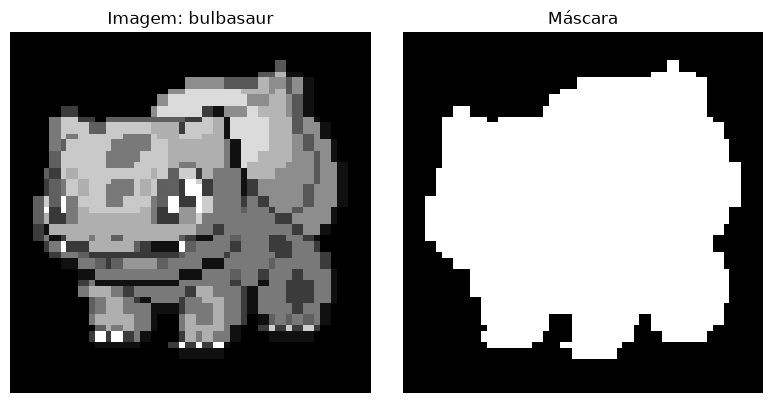

In [9]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Verificar caminhos encontrados
n_images = df_model["image_file"].notna().sum()
n_masks = df_model["mask_file"].notna().sum()

print(f"Imagens encontradas: {n_images}/{len(df_model)}")
print(f"Máscaras encontradas: {n_masks}/{len(df_model)}")

# Mostrar registros com caminhos inválidos, se existirem
invalid_paths = df_model[
    df_model["image_file"].isna() |
    df_model["mask_file"].isna()
]

print(f"\nRegistros com caminhos inválidos: {len(invalid_paths)}")

if len(invalid_paths) > 0:
    display(
        invalid_paths[
            ["id", "pokemon_name", "image_path", "mask_path"]
        ].head(10)
    )

# Selecionar um Pokémon do conjunto de treino
sample = df_model[df_model["split"] == "train"].iloc[0]

# Carregar imagem e máscara
image = np.asarray(
    Image.open(sample["image_file"]).convert("L"),
    dtype=np.float32
) / 255.0

mask = np.asarray(
    Image.open(sample["mask_file"]).convert("L"),
    dtype=np.uint8
)

mask = (mask > 127).astype(np.float32)

# Estatísticas
print(f"\nPokémon: {sample['pokemon_name']}")
print(f"ID: {sample['id']}")
print(f"Imagem: {image.shape}")
print(f"Máscara: {mask.shape}")
print(f"Intervalo da imagem: [{image.min():.3f}, {image.max():.3f}]")
print(f"Valores da máscara: {np.unique(mask)}")
print(f"Ocupação da máscara: {mask.mean() * 100:.2f}%")
print(f"Intensidade média fora da máscara: {image[mask == 0].mean():.6f}")

# Visualização
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(image, cmap="gray", vmin=0, vmax=1)
axes[0].set_title(f"Imagem: {sample['pokemon_name']}")
axes[0].axis("off")

axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Máscara")
axes[1].axis("off")

plt.tight_layout()
plt.show()

Preparação do dataset

In [30]:
import numpy as np
import torch

from torch.utils.data import Dataset, DataLoader
from PIL import Image


class PokemonAnalysisDataset(Dataset):

    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True).copy()

        self.conditions = self.df[CONDITION_COLS].values.astype(
            np.float32
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        # Abrir PNG original
        rgba = Image.open(row["raw_file"]).convert("RGBA")

        # Separar imagem e transparência
        gray = rgba.convert("RGB").convert("L")
        alpha = rgba.getchannel("A")

        # Redimensionar para 64x64
        gray = gray.resize(
            (64, 64),
            Image.Resampling.LANCZOS
        )

        alpha = alpha.resize(
            (64, 64),
            Image.Resampling.LANCZOS
        )

        # Converter imagem para [0, 1]
        image = np.asarray(
            gray,
            dtype=np.float32
        ) / 255.0

        # Reconstruir máscara binária
        alpha = np.asarray(alpha, dtype=np.uint8)
        mask = (alpha > 127).astype(np.float32)

        # Remover fundo
        image *= mask

        # Converter para tensores [1, 64, 64]
        image = torch.from_numpy(image).unsqueeze(0)
        mask = torch.from_numpy(mask).unsqueeze(0)

        condition = torch.from_numpy(
            self.conditions[idx]
        )

        return image, mask, condition


# Criar datasets separados
datasets = {}

for split in ["train", "validation", "test"]:

    split_df = df_model[df_model["split"] == split]

    datasets[split] = PokemonAnalysisDataset(split_df)


# Criar DataLoaders
dataloaders = {
    split: DataLoader(
        dataset,
        batch_size=32,
        shuffle=False,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda")
    )
    for split, dataset in datasets.items()
}


print("Tamanho dos datasets:")

for split, dataset in datasets.items():
    print(f"{split}: {len(dataset)} amostras")


# Testar um batch
images, masks, conditions = next(
    iter(dataloaders["train"])
)

print("\nDimensões do batch:")
print("Imagens:", images.shape)
print("Máscaras:", masks.shape)
print("Condições:", conditions.shape)

print("\nTipos:")
print("Imagens:", images.dtype)
print("Máscaras:", masks.dtype)
print("Condições:", conditions.dtype)

print("\nIntervalos:")
print(f"Imagem: [{images.min():.3f}, {images.max():.3f}]")
print(f"Máscara: {torch.unique(masks)}")
print(f"Condição: [{conditions.min():.3f}, {conditions.max():.3f}]")

# Verificações
assert images.shape == (32, 1, 64, 64)
assert masks.shape == (32, 1, 64, 64)
assert conditions.shape == (32, 24)

assert images.dtype == torch.float32
assert masks.dtype == torch.float32
assert conditions.dtype == torch.float32

print("\nDataset validado com sucesso!")

Tamanho dos datasets:
train: 905 amostras
validation: 60 amostras
test: 60 amostras

Dimensões do batch:
Imagens: torch.Size([32, 1, 64, 64])
Máscaras: torch.Size([32, 1, 64, 64])
Condições: torch.Size([32, 24])

Tipos:
Imagens: torch.float32
Máscaras: torch.float32
Condições: torch.float32

Intervalos:
Imagem: [0.000, 1.000]
Máscara: tensor([0., 1.])
Condição: [0.000, 1.000]

Dataset validado com sucesso!


In [12]:
# Carregar checkpoint na CPU apenas para inspeção
SPATIAL_CHECKPOINT_PATH = os.path.join(
    BASE_DIR,
    "cvae_spatial_16x16x16_best.pt"
)
checkpoint = torch.load(
    SPATIAL_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

print("Chaves do checkpoint:")
for key in checkpoint.keys():
    print(f"- {key}")

print("\nMetadados:")
for key, value in checkpoint.items():
    if key != "model_state_dict" and key != "optimizer_state_dict":
        print(f"{key}: {value}")

# Inspecionar os parâmetros da arquitetura
state_dict = checkpoint["model_state_dict"]

print("\nParâmetros do modelo:")
for name, tensor in state_dict.items():
    print(f"{name:55s} {tuple(tensor.shape)}")

print("\nTotal de tensores:", len(state_dict))

total_params = sum(
    tensor.numel()
    for tensor in state_dict.values()
)

print(f"Total de parâmetros: {total_params:,}")

Chaves do checkpoint:
- epoch
- model_state_dict
- optimizer_state_dict
- best_val_loss
- latent_channels
- latent_size
- latent_elements
- condition_dim
- kl_normalization
- reference_latent_dim
- lambda_bg
- beta_max
- beta_warmup_epochs
- logvar_limit
- seed

Metadados:
epoch: 73
best_val_loss: 172.66471824645996
latent_channels: 16
latent_size: 16
latent_elements: 4096
condition_dim: 24
kl_normalization: 32.0
reference_latent_dim: 128
lambda_bg: 0.1
beta_max: 1.0
beta_warmup_epochs: 40
logvar_limit: 6.0
seed: 42

Parâmetros do modelo:
encoder.features.0.weight                               (64, 25, 4, 4)
encoder.features.0.bias                                 (64,)
encoder.features.1.weight                               (64,)
encoder.features.1.bias                                 (64,)
encoder.features.1.running_mean                         (64,)
encoder.features.1.running_var                          (64,)
encoder.features.1.num_batches_tracked                  ()
encoder.feature

Modelo UltraBall

In [13]:
class SpatialEncoder16(nn.Module):

    def __init__(
        self,
        condition_dim=24,
        latent_channels=16
    ):

        super().__init__()

        self.features = nn.Sequential(

            # 64x64 -> 32x32
            nn.Conv2d(
                1 + condition_dim,
                64,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2, inplace=True),

            # 32x32 -> 16x16
            nn.Conv2d(
                64,
                128,
                kernel_size=4,
                stride=2,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),

            # Refinamento espacial 16x16
            nn.Conv2d(
                128,
                192,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.BatchNorm2d(192),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                192,
                192,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.BatchNorm2d(192),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(
                192,
                192,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.BatchNorm2d(192),
            nn.LeakyReLU(0.2, inplace=True),

            # Preparar representação latente
            nn.Conv2d(
                192,
                128,
                kernel_size=1
            ),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True)
        )

        # Projeções espaciais para os parâmetros da distribuição
        self.mu_head = nn.Conv2d(
            128,
            latent_channels,
            kernel_size=1
        )

        self.logvar_head = nn.Conv2d(
            128,
            latent_channels,
            kernel_size=1
        )

        # Inicialização pequena da média
        nn.init.xavier_uniform_(
            self.mu_head.weight,
            gain=0.1
        )

        nn.init.zeros_(
            self.mu_head.bias
        )

        # Inicializar logvar em zero:
        # distribuição inicial próxima de N(0, I)
        nn.init.zeros_(
            self.logvar_head.weight
        )

        nn.init.zeros_(
            self.logvar_head.bias
        )

    def forward(self, x, c):

        batch_size = x.size(0)

        height = x.size(2)
        width = x.size(3)

        # Expandir condições espacialmente
        c_map = c.unsqueeze(-1).unsqueeze(-1)

        c_map = c_map.expand(
            batch_size,
            c.size(1),
            height,
            width
        )

        # Concatenar imagem e condições
        x = torch.cat(
            [x, c_map],
            dim=1
        )

        # Extração espacial
        features = self.features(x)

        # Parâmetros da distribuição latente
        mu = self.mu_head(features)

        raw_logvar = self.logvar_head(features)

        # Estabilização suave
        LOGVAR_LIMIT = 6.0

        logvar = LOGVAR_LIMIT * torch.tanh(
            raw_logvar / LOGVAR_LIMIT
        )

        return mu, logvar

class SpatialDecoder16(nn.Module):

    def __init__(
        self,
        latent_channels=16,
        condition_dim=24
    ):

        super().__init__()

        input_channels = latent_channels + condition_dim

        self.initial = nn.Sequential(

            nn.Conv2d(
                input_channels,
                192,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.BatchNorm2d(192),
            nn.ReLU(inplace=True)
        )

        # Refinamento em 16x16
        self.refine = nn.Sequential(

            nn.Conv2d(
                192,
                192,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(192),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                192,
                192,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(192),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                192,
                128,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True)
        )

        # 16x16 -> 32x32
        self.up32 = nn.Sequential(

            nn.Upsample(
                scale_factor=2,
                mode="nearest"
            ),

            nn.Conv2d(
                128,
                96,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(96),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                96,
                96,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(96),
            nn.ReLU(inplace=True)
        )

        # 32x32 -> 64x64
        self.up64 = nn.Sequential(

            nn.Upsample(
                scale_factor=2,
                mode="nearest"
            ),

            nn.Conv2d(
                96,
                64,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                64,
                32,
                kernel_size=3,
                padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True)
        )

        # Refinamento final e saída grayscale
        self.output = nn.Sequential(

            nn.Conv2d(
                32,
                1,
                kernel_size=3,
                padding=1
            ),

            nn.Sigmoid()
        )

    def forward(self, z, c):

        batch_size = z.size(0)

        height = z.size(2)
        width = z.size(3)

        # Expandir condições para 16x16
        c_map = c.unsqueeze(-1).unsqueeze(-1)

        c_map = c_map.expand(
            batch_size,
            c.size(1),
            height,
            width
        )

        # Concatenar latente e condições
        x = torch.cat(
            [z, c_map],
            dim=1
        )

        x = self.initial(x)

        x = self.refine(x)

        x = self.up32(x)

        x = self.up64(x)

        reconstruction = self.output(x)

        return reconstruction

class CVAESpatial16(nn.Module):

    def __init__(
        self,
        condition_dim=24,
        latent_channels=16,
        latent_size=16
    ):
        super().__init__()

        self.condition_dim = condition_dim
        self.latent_channels = latent_channels
        self.latent_size = latent_size

        self.encoder = SpatialEncoder16(
            condition_dim=condition_dim,
            latent_channels=latent_channels
        )

        self.decoder = SpatialDecoder16(
            condition_dim=condition_dim,
            latent_channels=latent_channels
        )

    def reparameterize(self, mu, logvar):

        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)

        return mu + epsilon * std

    def forward(self, x, condition):

        mu, logvar = self.encoder(x, condition)

        z = self.reparameterize(mu, logvar)

        reconstruction = self.decoder(z, condition)

        return reconstruction, mu, logvar

    def reconstruct(self, x, condition):

        # Reconstrução determinística usando mu
        mu, _ = self.encoder(x, condition)

        return self.decoder(mu, condition)

    def generate(self, condition, z=None):

        batch_size = condition.shape[0]

        if z is None:
            z = torch.randn(
                batch_size,
                self.latent_channels,
                self.latent_size,
                self.latent_size,
                device=condition.device,
                dtype=condition.dtype
            )

        return self.decoder(z, condition)

Carregamento do modelo

In [14]:
model = CVAESpatial16(
    condition_dim=checkpoint["condition_dim"],
    latent_channels=checkpoint["latent_channels"],
    latent_size=checkpoint["latent_size"]
).to(DEVICE)

# Carregar todos os parâmetros
load_result = model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model.eval()

# Quantidade de parâmetros treináveis
total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Checkpoint carregado com sucesso!")
print("Resultado do carregamento:", load_result)

print(f"\nParâmetros treináveis: {total_params:,}")
print(f"Dispositivo: {next(model.parameters()).device}")
print(f"Modo de treinamento: {model.training}")

Checkpoint carregado com sucesso!
Resultado do carregamento: <All keys matched successfully>

Parâmetros treináveis: 2,297,185
Dispositivo: cuda:0
Modo de treinamento: False


In [15]:
# Obter um batch do teste
images, masks, conditions = next(
    iter(dataloaders["test"])
)

images = images.to(DEVICE)
masks = masks.to(DEVICE)
conditions = conditions.to(DEVICE)

model.eval()

with torch.no_grad():

    # Forward completo
    reconstructions, mu, logvar = model(
        images,
        conditions
    )

    # Reconstrução determinística
    reconstructions_mu = model.reconstruct(
        images,
        conditions
    )

    # Geração a partir do prior
    generated = model.generate(conditions)

print("Dimensões dos tensores:")
print("Imagem original:", images.shape)
print("Máscara:", masks.shape)
print("Condições:", conditions.shape)
print("Reconstrução:", reconstructions.shape)
print("Mu:", mu.shape)
print("Logvar:", logvar.shape)
print("Geração:", generated.shape)

print("\nIntervalos:")
print(
    f"Reconstrução: [{reconstructions.min().item():.4f}, "
    f"{reconstructions.max().item():.4f}]"
)
print(
    f"Geração: [{generated.min().item():.4f}, "
    f"{generated.max().item():.4f}]"
)

assert reconstructions.shape == images.shape
assert mu.shape == (32, 16, 16, 16)
assert logvar.shape == mu.shape
assert generated.shape == images.shape

print("\nModelo validado com sucesso!")

Dimensões dos tensores:
Imagem original: torch.Size([32, 1, 64, 64])
Máscara: torch.Size([32, 1, 64, 64])
Condições: torch.Size([32, 24])
Reconstrução: torch.Size([32, 1, 64, 64])
Mu: torch.Size([32, 16, 16, 16])
Logvar: torch.Size([32, 16, 16, 16])
Geração: torch.Size([32, 1, 64, 64])

Intervalos:
Reconstrução: [0.0000, 0.9974]
Geração: [0.0000, 0.9972]

Modelo validado com sucesso!


Teste de reconstrução

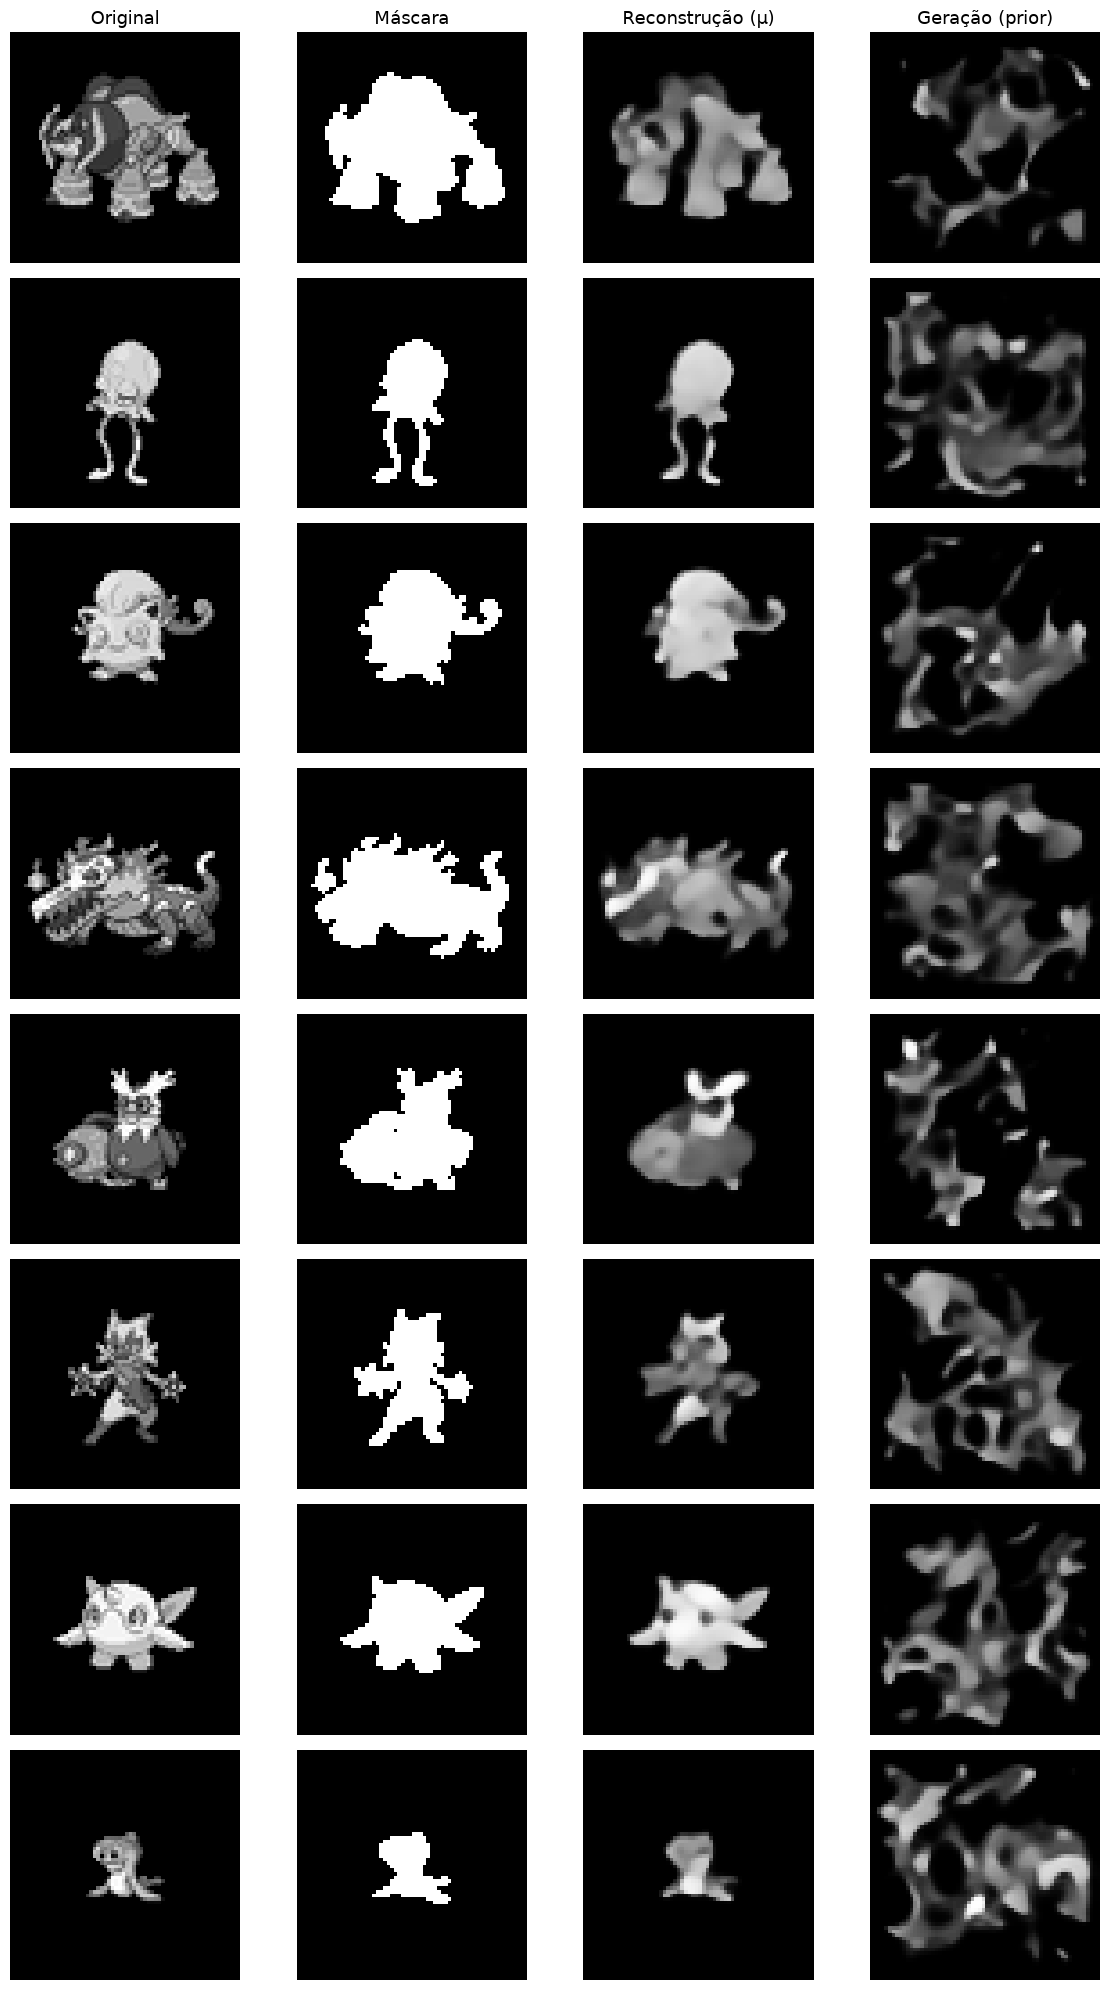

In [35]:
import matplotlib.pyplot as plt

# Quantidade de Pokémon que serão visualizados
N = 8

# Selecionar um batch do conjunto de teste
images, masks, conditions = next(
    iter(dataloaders["test"])
)

images = images[:N].to(DEVICE)
masks = masks[:N].to(DEVICE)
conditions = conditions[:N].to(DEVICE)

# Nomes correspondentes às amostras
test_names = (
    df_model[df_model["split"] == "test"]
    ["pokemon_name"]
    .iloc[:N]
    .tolist()
)

model.eval()

with torch.no_grad():

    # Reconstrução utilizando mu
    reconstructions = model.reconstruct(
        images,
        conditions
    )

    # Geração utilizando o prior
    generated = model.generate(
        conditions
    )


# Transferir para CPU para visualização
images_np = images.cpu().numpy()
masks_np = masks.cpu().numpy()
recon_np = reconstructions.cpu().numpy()
generated_np = generated.cpu().numpy()


# Visualização
fig, axes = plt.subplots(
    N, 4,
    figsize=(12, 2.5 * N)
)

column_titles = [
    "Original",
    "Máscara",
    "Reconstrução (μ)",
    "Geração (prior)"
]

for col, title in enumerate(column_titles):
    axes[0, col].set_title(title, fontsize=13)

for i in range(N):

    samples = [
        images_np[i, 0],
        masks_np[i, 0],
        recon_np[i, 0],
        generated_np[i, 0]
    ]

    for j, sample in enumerate(samples):

        axes[i, j].imshow(
            sample,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[i, j].axis("off")

    axes[i, 0].set_ylabel(
        test_names[i],
        rotation=0,
        labelpad=45,
        fontsize=10,
        va="center"
    )

plt.tight_layout()
plt.show()

In [17]:
import numpy as np
import torch

model.eval()

# Acumuladores globais
total_fg_error = 0.0
total_bg_error = 0.0

total_fg_pixels = 0
total_bg_pixels = 0

# Métricas individuais
sample_fg_mae = []
sample_bg_mae = []

with torch.no_grad():

    for images, masks, conditions in dataloaders["test"]:

        images = images.to(DEVICE)
        masks = masks.to(DEVICE)
        conditions = conditions.to(DEVICE)

        # Reconstrução determinística usando mu
        reconstructions = model.reconstruct(
            images,
            conditions
        )

        errors = torch.abs(reconstructions - images)

        # Erro dentro da silhueta
        fg_errors = errors * masks

        # Erro fora da silhueta
        bg_errors = errors * (1 - masks)

        # Acumuladores globais
        total_fg_error += fg_errors.sum().item()
        total_bg_error += bg_errors.sum().item()

        total_fg_pixels += masks.sum().item()
        total_bg_pixels += (1 - masks).sum().item()

        # MAE individual por Pokémon
        for i in range(images.shape[0]):

            fg_count = masks[i].sum().item()
            bg_count = (1 - masks[i]).sum().item()

            fg_mae = (
                fg_errors[i].sum().item() / fg_count
            )

            bg_mae = (
                bg_errors[i].sum().item() / bg_count
            )

            sample_fg_mae.append(fg_mae)
            sample_bg_mae.append(bg_mae)


# Métricas globais
fg_mae = total_fg_error / total_fg_pixels
bg_mae = total_bg_error / total_bg_pixels

print("=" * 45)
print("AVALIAÇÃO DAS RECONSTRUÇÕES - TESTE")
print("=" * 45)

print(f"Foreground MAE: {fg_mae:.6f}")
print(f"Background MAE: {bg_mae:.6f}")

print("\nVariação entre Pokémon:")

print(
    f"Foreground MAE: "
    f"{np.mean(sample_fg_mae):.6f} "
    f"+/- {np.std(sample_fg_mae):.6f}"
)

print(
    f"Background MAE: "
    f"{np.mean(sample_bg_mae):.6f} "
    f"+/- {np.std(sample_bg_mae):.6f}"
)

print("\nPercentis do erro no foreground:")

for q in [0, 25, 50, 75, 100]:

    value = np.percentile(sample_fg_mae, q)

    print(f"P{q}: {value:.6f}")

AVALIAÇÃO DAS RECONSTRUÇÕES - TESTE
Foreground MAE: 0.116955
Background MAE: 0.007084

Variação entre Pokémon:
Foreground MAE: 0.118406 +/- 0.027027
Background MAE: 0.007106 +/- 0.004313

Percentis do erro no foreground:
P0: 0.062110
P25: 0.098675
P50: 0.118121
P75: 0.138498
P100: 0.185817


In [18]:
import torch
import pandas as pd
import numpy as np

model.eval()

all_mu = []
all_logvar = []

with torch.no_grad():

    for images, masks, conditions in dataloaders["test"]:

        images = images.to(DEVICE)
        conditions = conditions.to(DEVICE)

        # Extrair parâmetros da distribuição posterior
        mu, logvar = model.encoder(images, conditions)

        all_mu.append(mu.cpu())
        all_logvar.append(logvar.cpu())


# Formatos: [60, 16, 16, 16]
mu_all = torch.cat(all_mu, dim=0)
logvar_all = torch.cat(all_logvar, dim=0)

var_all = torch.exp(logvar_all)

print("Dimensões:")
print("Mu:", mu_all.shape)
print("Logvar:", logvar_all.shape)
print("Variância:", var_all.shape)

print("\nEstatísticas globais:")

print(f"Mean mu: {mu_all.mean().item():.6f}")
print(f"Std mu: {mu_all.std(unbiased=False).item():.6f}")

print(f"Mean logvar: {logvar_all.mean().item():.6f}")
print(f"Mean posterior variance: {var_all.mean().item():.6f}")
print(f"Mean posterior std: {torch.sqrt(var_all).mean().item():.6f}")

Dimensões:
Mu: torch.Size([60, 16, 16, 16])
Logvar: torch.Size([60, 16, 16, 16])
Variância: torch.Size([60, 16, 16, 16])

Estatísticas globais:
Mean mu: 0.001614
Std mu: 0.228442
Mean logvar: -0.207574
Mean posterior variance: 0.945099
Mean posterior std: 0.955674


In [19]:
# Reduzir batch e dimensões espaciais, preservando os canais
dims = (0, 2, 3)

channel_mu_mean = mu_all.mean(dim=dims)
channel_mu_std = mu_all.std(dim=dims, unbiased=False)

channel_logvar_mean = logvar_all.mean(dim=dims)
channel_var_mean = var_all.mean(dim=dims)

# Variância marginal agregada por canal
channel_aggregate_var = (
    (mu_all.pow(2) + var_all).mean(dim=dims)
    - channel_mu_mean.pow(2)
).clamp(min=0)

channel_aggregate_std = torch.sqrt(channel_aggregate_var)

# KL por elemento latente
kl_element = -0.5 * (
    1 + logvar_all - mu_all.pow(2) - var_all
)

# Soma espacial, média entre amostras
kl_per_channel = kl_element.sum(dim=(0, 2, 3)) / len(mu_all)

kl_total_raw = kl_per_channel.sum()
kl_total_normalized = kl_total_raw / checkpoint["kl_normalization"]

kl_percentage = (
    kl_per_channel / kl_total_raw.clamp(min=1e-12)
) * 100


# Montar tabela
latent_analysis = pd.DataFrame({
    "channel": np.arange(16),
    "mu_mean": channel_mu_mean.numpy(),
    "mu_std": channel_mu_std.numpy(),
    "mean_logvar": channel_logvar_mean.numpy(),
    "mean_variance": channel_var_mean.numpy(),
    "aggregate_std": channel_aggregate_std.numpy(),
    "kl_raw": kl_per_channel.numpy(),
    "kl_percentage": kl_percentage.numpy()
})

latent_analysis = latent_analysis.sort_values(
    "kl_raw",
    ascending=False
).reset_index(drop=True)

display(
    latent_analysis.style.format({
        "mu_mean": "{:.5f}",
        "mu_std": "{:.5f}",
        "mean_logvar": "{:.5f}",
        "mean_variance": "{:.5f}",
        "aggregate_std": "{:.5f}",
        "kl_raw": "{:.5f}",
        "kl_percentage": "{:.2f}%"
    })
)

print(f"KL total bruto: {kl_total_raw.item():.5f}")
print(f"KL total normalizado: {kl_total_normalized.item():.5f}")

,channel,mu_mean,mu_std,mean_logvar,mean_variance,aggregate_std,kl_raw,kl_percentage
0,5,0.02564,0.91266,-3.21858,0.22350,1.02783,419.28610,99.94%
1,12,-0.00076,0.02219,-0.01119,0.98895,0.99471,0.08114,0.02%
2,13,0.00015,0.01540,-0.01093,0.98918,0.99469,0.04448,0.01%
3,7,-0.00015,0.00925,-0.00483,0.99520,0.99764,0.01501,0.00%
4,3,0.00122,0.00734,-0.00908,0.99098,0.99551,0.01422,0.00%
5,1,-0.00016,0.00957,-0.00462,0.99540,0.99774,0.01411,0.00%
6,4,0.00030,0.00871,-0.00670,0.99334,0.99670,0.01399,0.00%
7,11,-0.00025,0.00786,-0.00581,0.99422,0.99714,0.01176,0.00%
8,8,0.00041,0.00682,-0.00767,0.99237,0.99620,0.01109,0.00%
9,0,-0.00012,0.00620,-0.00598,0.99406,0.99705,0.01048,0.00%


KL total bruto: 419.55597
KL total normalizado: 13.11112


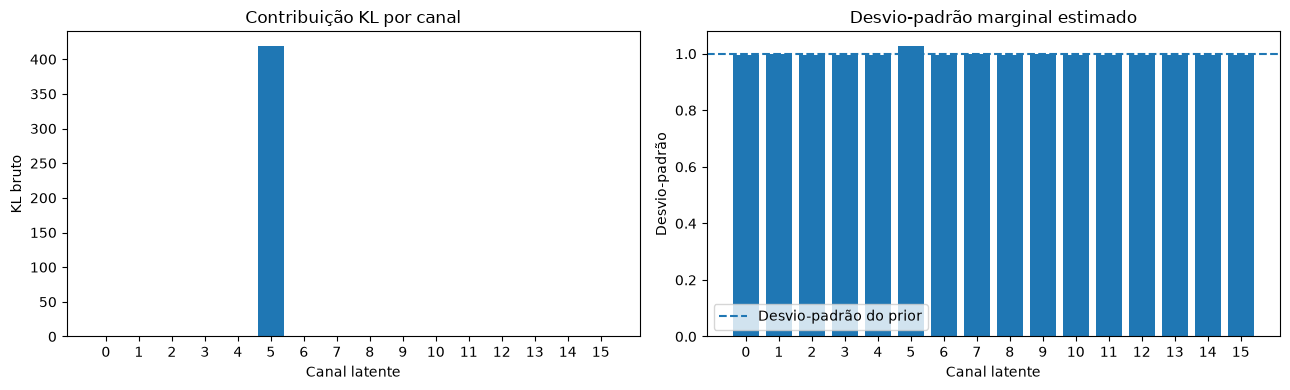

In [20]:
import matplotlib.pyplot as plt

# Ordenar canais pelo índice original
latent_by_channel = latent_analysis.sort_values("channel")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Contribuição de cada canal para KL
axes[0].bar(
    latent_by_channel["channel"],
    latent_by_channel["kl_raw"]
)

axes[0].set_title("Contribuição KL por canal")
axes[0].set_xlabel("Canal latente")
axes[0].set_ylabel("KL bruto")
axes[0].set_xticks(range(16))

# Desvio-padrão da distribuição agregada
axes[1].bar(
    latent_by_channel["channel"],
    latent_by_channel["aggregate_std"]
)

axes[1].axhline(
    1.0,
    linestyle="--",
    label="Desvio-padrão do prior"
)

axes[1].set_title("Desvio-padrão marginal estimado")
axes[1].set_xlabel("Canal latente")
axes[1].set_ylabel("Desvio-padrão")
axes[1].set_xticks(range(16))
axes[1].legend()

plt.tight_layout()
plt.show()

In [22]:
from pathlib import Path

def get_filename(path):
    # Trata tanto separadores Windows quanto Unix
    return str(path).replace("\\", "/").rstrip("/").split("/")[-1]


# Reconstruir os caminhos absolutos
df_model["image_file"] = df_model["image_path"].apply(
    lambda p: BASE_DIR / "processed_masked" / get_filename(p)
)

df_model["mask_file"] = df_model["mask_path"].apply(
    lambda p: BASE_DIR / "masks" / get_filename(p)
)


# Verificar novamente todos os arquivos
missing_images = df_model[
    ~df_model["image_file"].apply(lambda p: p.is_file())
]

missing_masks = df_model[
    ~df_model["mask_file"].apply(lambda p: p.is_file())
]

print("Diretório base:", BASE_DIR.resolve())

print(f"\nImagens encontradas: {len(df_model) - len(missing_images)}/{len(df_model)}")
print(f"Máscaras encontradas: {len(df_model) - len(missing_masks)}/{len(df_model)}")

print("\nExemplo de caminho absoluto:")
print(df_model.iloc[0]["image_file"])

Diretório base: C:\Mestrado\Projeto_poke_sprite\poke_sprite

Imagens encontradas: 0/1025
Máscaras encontradas: 0/1025

Exemplo de caminho absoluto:
c:\Mestrado\Projeto_poke_sprite\poke_sprite\processed_masked\0001_bulbasaur.png


In [26]:
from pathlib import Path
from PIL import Image

def get_filename(path):
    return str(path).replace("\\", "/").rstrip("/").split("/")[-1]


# Caminhos reais das imagens originais
df_model["raw_file"] = df_model["raw_path"].apply(
    lambda p: BASE_DIR / "raw" / get_filename(p)
)

# Verificar existência
print(
    "Imagens RAW:",
    df_model["raw_file"].apply(lambda p: p.is_file()).sum(),
    "/", len(df_model)
)

# Verificar pasta de máscaras
mask_dir = BASE_DIR / "masks"

print("Pasta masks existe:", mask_dir.exists())

print(
    "Máscaras encontradas:",
    df_model["mask_file"].apply(lambda p: p.is_file()).sum(),
    "/", len(df_model)
)

# Inspecionar algumas imagens originais
for _, row in df_model.head(5).iterrows():

    path = row["raw_file"]

    with Image.open(path) as img:
        print(
            f"{row['pokemon_name']}: "
            f"modo={img.mode}, "
            f"dimensões={img.size}, "
            f"arquivo={path.name}"
        )

Imagens RAW: 1025 / 1025
Pasta masks existe: False
Máscaras encontradas: 0 / 1025
bulbasaur: modo=RGBA, dimensões=(96, 96), arquivo=0001_bulbasaur.png
ivysaur: modo=RGBA, dimensões=(96, 96), arquivo=0002_ivysaur.png
venusaur: modo=RGBA, dimensões=(96, 96), arquivo=0003_venusaur.png
charmander: modo=RGBA, dimensões=(96, 96), arquivo=0004_charmander.png
charmeleon: modo=RGBA, dimensões=(96, 96), arquivo=0005_charmeleon.png


In [ ]:
datasets = {
    split: PokemonAnalysisDataset(
        df_model[df_model["split"] == split]
    )
    for split in ["train", "validation", "test"]
}

dataloaders = {
    split: DataLoader(
        dataset,
        batch_size=32,
        shuffle=False,
        num_workers=0,
        pin_memory=(DEVICE.type == "cuda")
    )
    for split, dataset in datasets.items()
}

print("DataLoaders atualizados!")

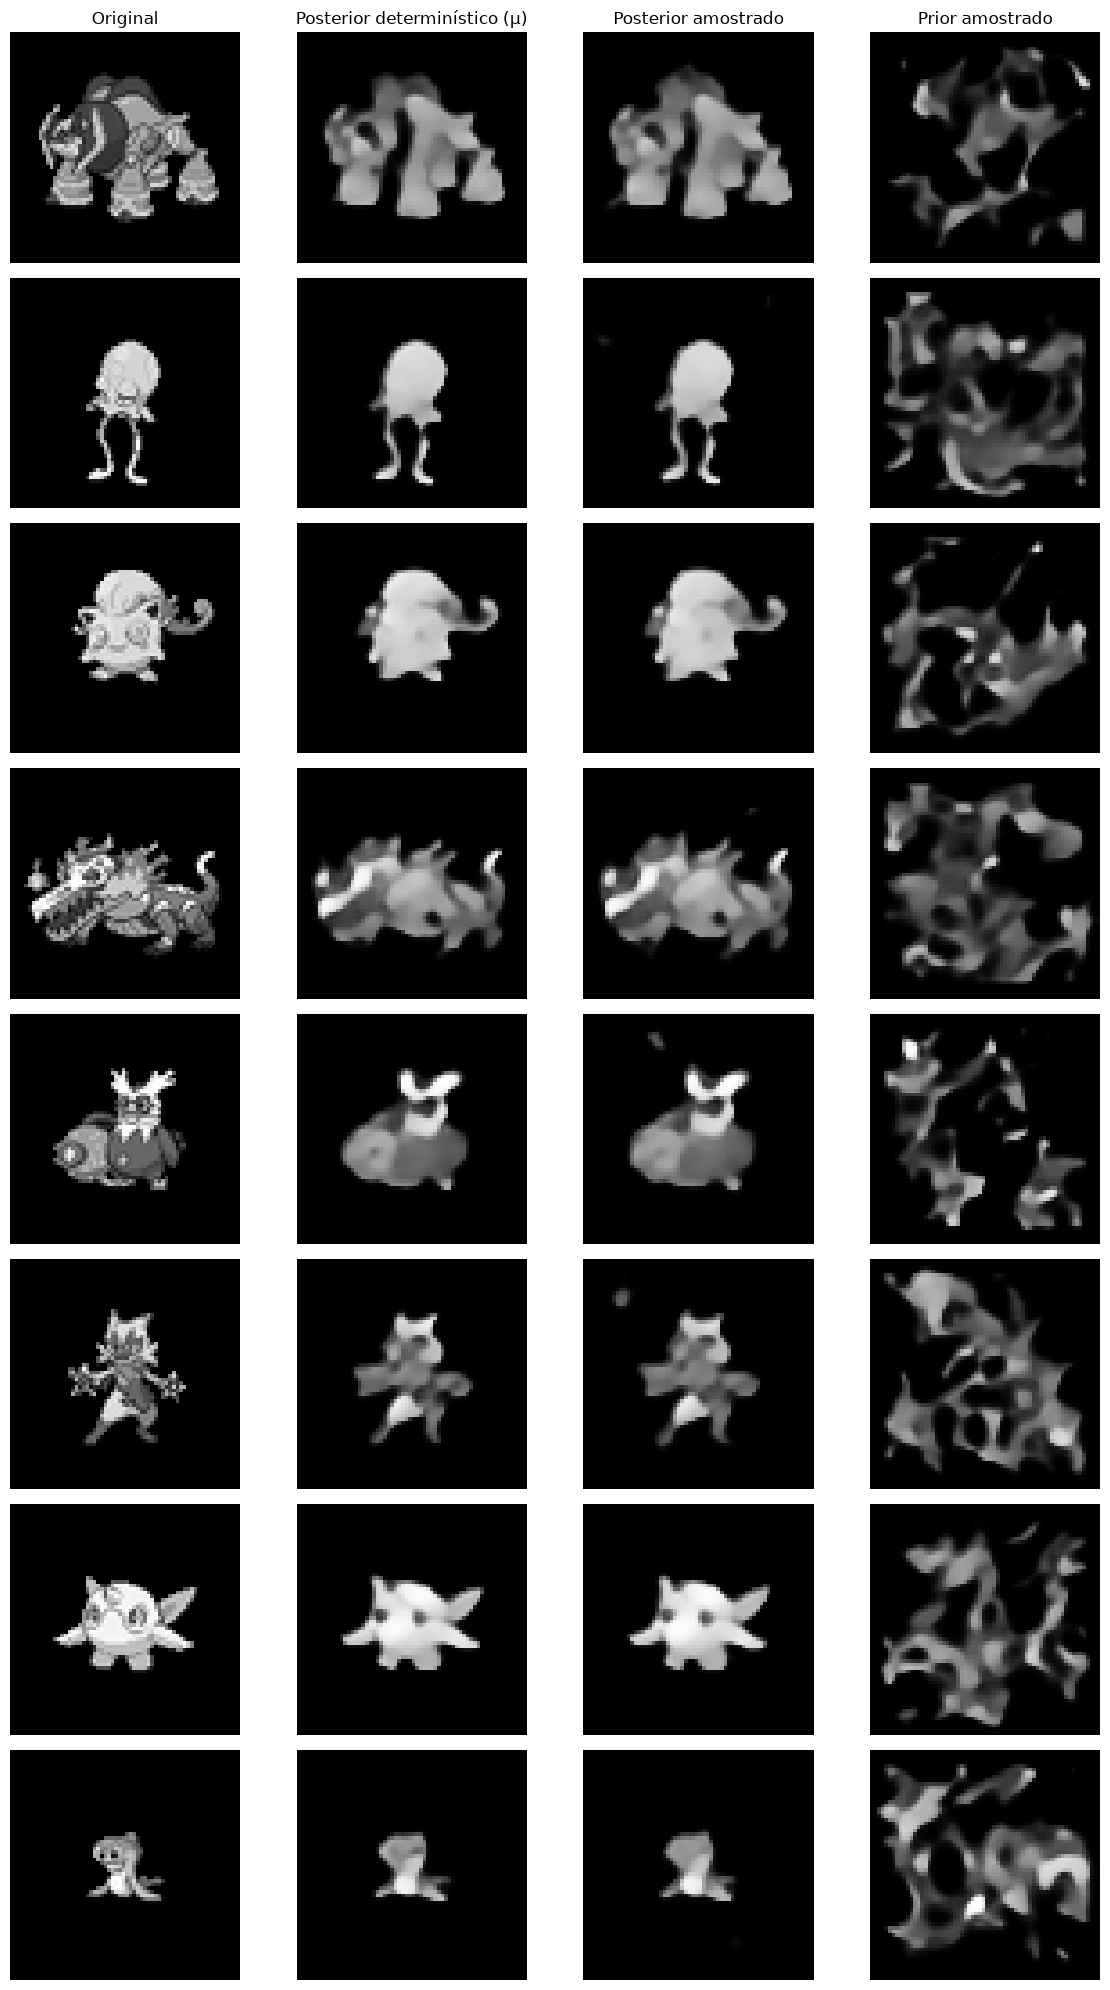

In [31]:
import matplotlib.pyplot as plt
import torch

N = 8

# Selecionar os mesmos exemplos do conjunto de teste
images, masks, conditions = next(
    iter(dataloaders["test"])
)

images = images[:N].to(DEVICE)
conditions = conditions[:N].to(DEVICE)

test_names = (
    df_model[df_model["split"] == "test"]
    ["pokemon_name"]
    .iloc[:N]
    .tolist()
)

model.eval()

with torch.no_grad():

    # Obter distribuição posterior
    mu, logvar = model.encoder(images, conditions)

    # 1. Posterior determinístico
    reconstruction_mu = model.decoder(
        mu,
        conditions
    )

    # 2. Amostra da distribuição posterior
    z_posterior = model.reparameterize(
        mu,
        logvar
    )

    generation_posterior = model.decoder(
        z_posterior,
        conditions
    )

    # 3. Amostra do prior
    z_prior = torch.randn_like(mu)

    generation_prior = model.decoder(
        z_prior,
        conditions
    )


# Converter para CPU
images_np = images.cpu().numpy()
mu_np = reconstruction_mu.cpu().numpy()
posterior_np = generation_posterior.cpu().numpy()
prior_np = generation_prior.cpu().numpy()


# Visualização
fig, axes = plt.subplots(
    N, 4,
    figsize=(12, 2.5 * N)
)

titles = [
    "Original",
    "Posterior determinístico (μ)",
    "Posterior amostrado",
    "Prior amostrado"
]

for j, title in enumerate(titles):
    axes[0, j].set_title(title, fontsize=12)

for i in range(N):

    samples = [
        images_np[i, 0],
        mu_np[i, 0],
        posterior_np[i, 0],
        prior_np[i, 0]
    ]

    for j, sample in enumerate(samples):

        axes[i, j].imshow(
            sample,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[i, j].axis("off")

    axes[i, 0].set_ylabel(
        test_names[i],
        rotation=0,
        labelpad=45,
        va="center"
    )

plt.tight_layout()
plt.show()

In [36]:
import numpy as np
import torch

model.eval()

posterior_differences = []
prior_differences = []

# Reprodutibilidade das amostras
torch.manual_seed(42)

with torch.no_grad():

    for images, masks, conditions in dataloaders["test"]:

        images = images.to(DEVICE)
        conditions = conditions.to(DEVICE)

        # Obter distribuição posterior
        mu, logvar = model.encoder(images, conditions)

        # 1. Saída determinística
        reconstruction_mu = model.decoder(
            mu,
            conditions
        )

        # 2. Amostra posterior
        z_posterior = model.reparameterize(
            mu,
            logvar
        )

        generation_posterior = model.decoder(
            z_posterior,
            conditions
        )

        # 3. Amostra do prior
        z_prior = torch.randn_like(mu)

        generation_prior = model.decoder(
            z_prior,
            conditions
        )

        # Diferença média por Pokémon
        diff_posterior = (
            generation_posterior - reconstruction_mu
        ).abs().mean(dim=(1, 2, 3))

        diff_prior = (
            generation_prior - reconstruction_mu
        ).abs().mean(dim=(1, 2, 3))

        posterior_differences.extend(
            diff_posterior.cpu().numpy()
        )

        prior_differences.extend(
            diff_prior.cpu().numpy()
        )


# Converter para arrays
posterior_differences = np.array(posterior_differences)
prior_differences = np.array(prior_differences)


print("=" * 50)
print("SENSIBILIDADE DO DECODER À AMOSTRAGEM LATENTE")
print("=" * 50)

print("\nPosterior amostrado vs. determinístico:")
print(f"MAE médio: {posterior_differences.mean():.6f}")
print(f"Desvio-padrão: {posterior_differences.std():.6f}")

print("\nPrior amostrado vs. determinístico:")
print(f"MAE médio: {prior_differences.mean():.6f}")
print(f"Desvio-padrão: {prior_differences.std():.6f}")

print("\nComparação:")
print(
    "Razão entre as diferenças:",
    f"{prior_differences.mean() / max(posterior_differences.mean(), 1e-12):.2f}x"
)

SENSIBILIDADE DO DECODER À AMOSTRAGEM LATENTE

Posterior amostrado vs. determinístico:
MAE médio: 0.007999
Desvio-padrão: 0.003800

Prior amostrado vs. determinístico:
MAE médio: 0.147277
Desvio-padrão: 0.030747

Comparação:
Razão entre as diferenças: 18.41x


RESULTADOS DA ABLACAO DO CANAL LATENTE 5
posterior_vs_posterior_sem_canal5            : 0.147291 +/- 0.027480
prior_vs_prior_com_canal5                    : 0.147315 +/- 0.027468
posterior_vs_mu                              : 0.007938 +/- 0.003748
posterior_sem_canal5_vs_mu                   : 0.148903 +/- 0.027765
prior_vs_mu                                  : 0.148923 +/- 0.027753
prior_com_canal5_vs_mu                       : 0.007971 +/- 0.003775


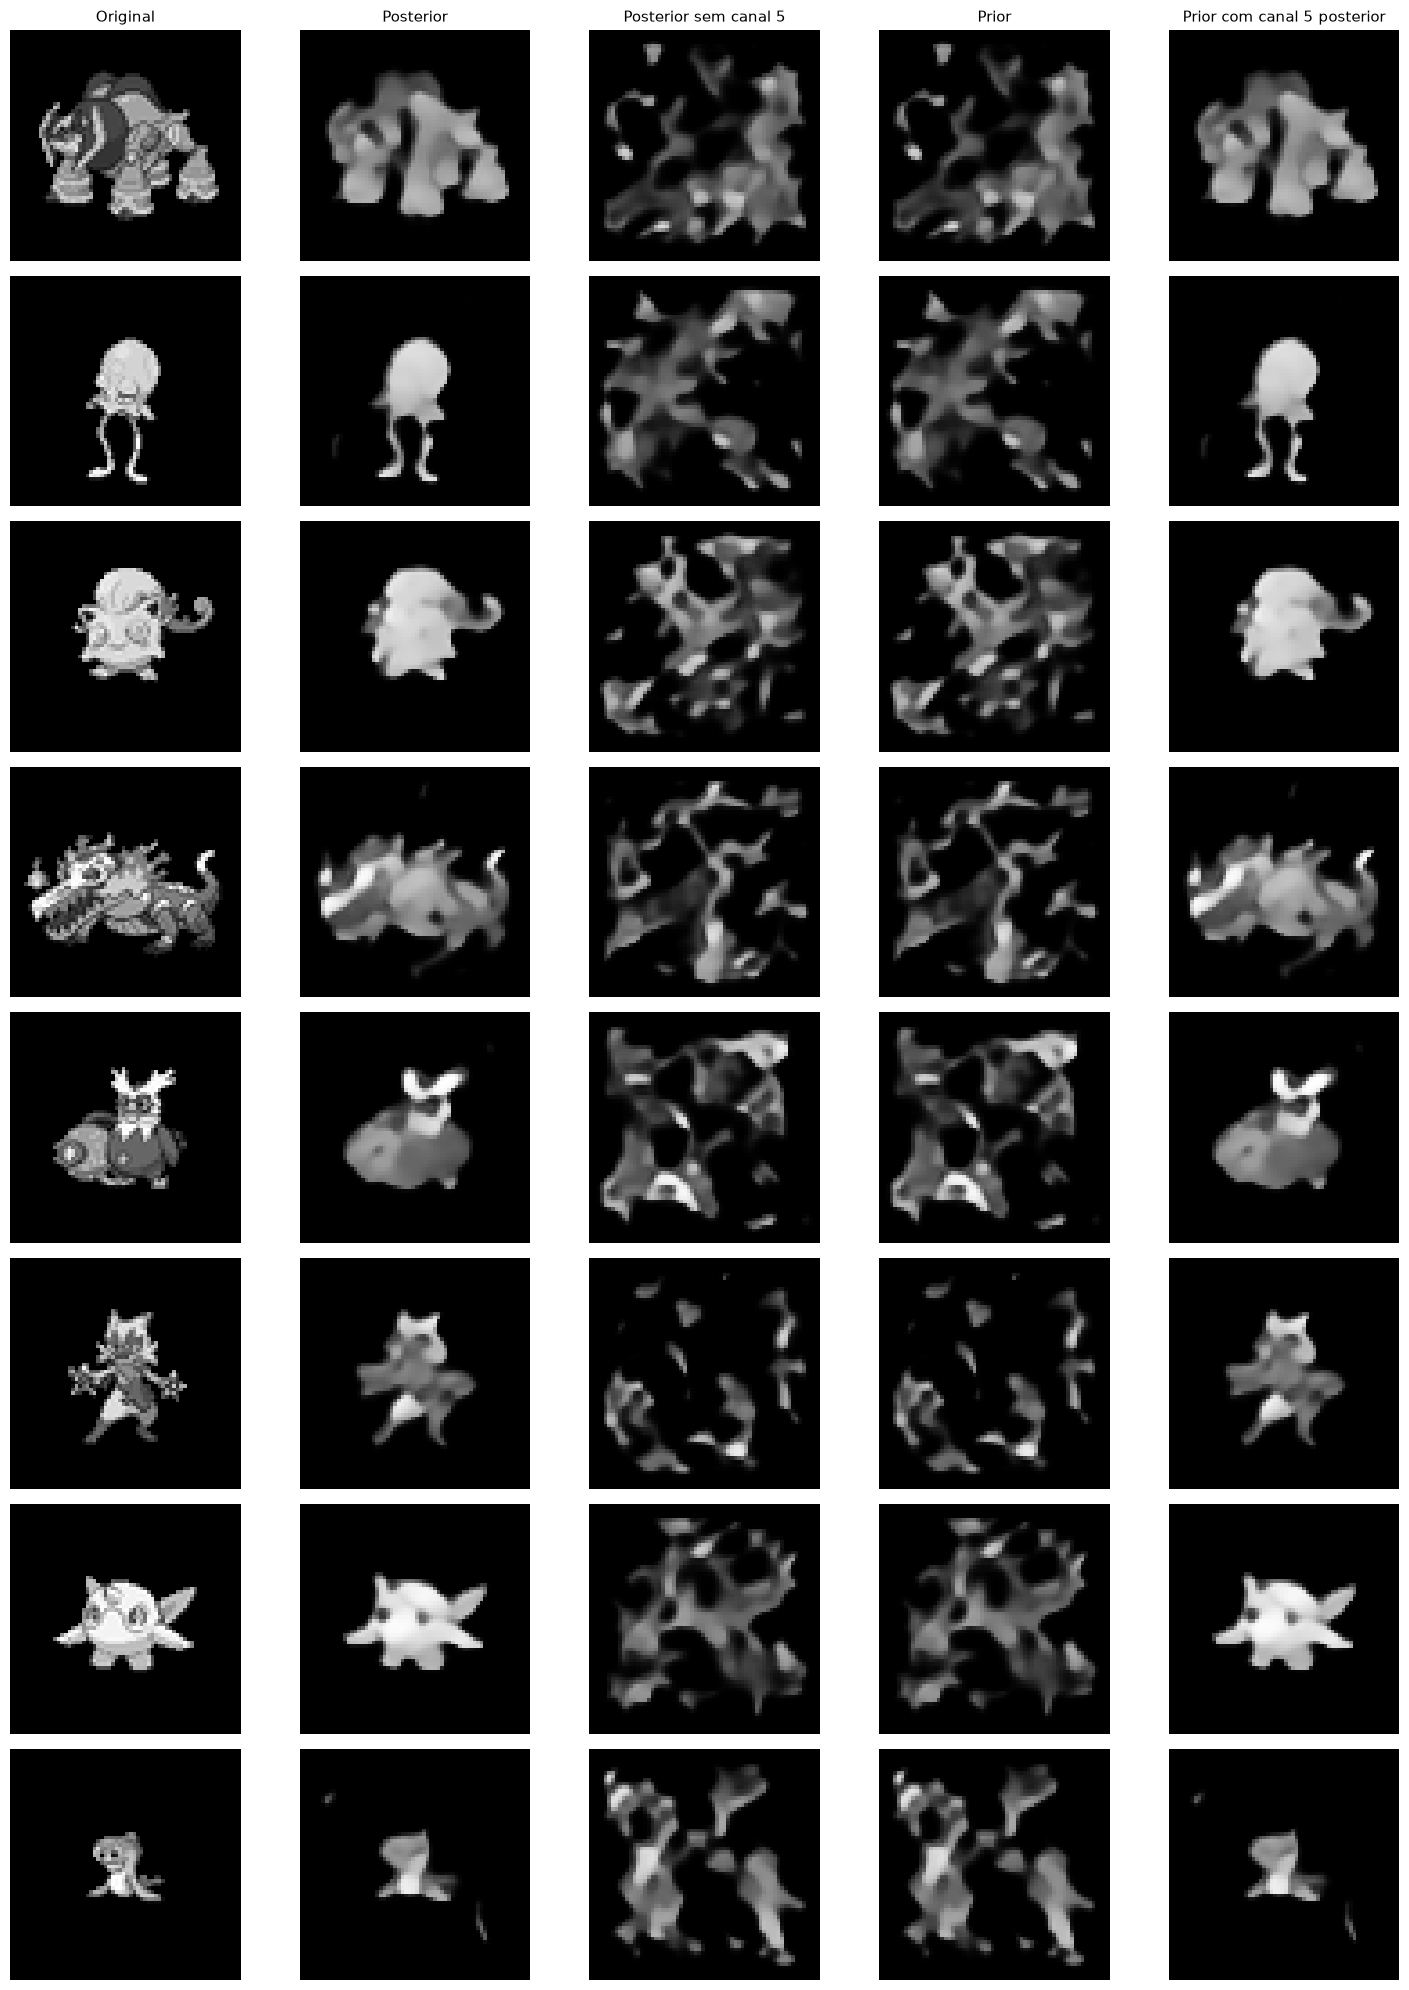

In [37]:
import numpy as np
import torch
import matplotlib.pyplot as plt

N = 8
LATENT_CHANNEL = 5

model.eval()

torch.manual_seed(42)

# Para guardar os resultados quantitativos
metrics = {
    "posterior_vs_posterior_sem_canal5": [],
    "prior_vs_prior_com_canal5": [],
    "posterior_vs_mu": [],
    "posterior_sem_canal5_vs_mu": [],
    "prior_vs_mu": [],
    "prior_com_canal5_vs_mu": []
}

# Guardar as primeiras amostras para visualização
visual_results = {
    "original": [],
    "posterior": [],
    "posterior_sem_canal5": [],
    "prior": [],
    "prior_com_canal5": []
}

with torch.no_grad():

    for images, masks, conditions in dataloaders["test"]:

        images = images.to(DEVICE)
        conditions = conditions.to(DEVICE)

        # Obter distribuição posterior
        mu, logvar = model.encoder(images, conditions)

        std = torch.exp(0.5 * logvar)

        # Gerar um ruído compartilhado
        epsilon = torch.randn_like(mu)

        # Amostra posterior
        z_posterior = mu + epsilon * std

        # Amostra do prior
        z_prior = epsilon

        # Posterior com canal 5 substituído pelo prior
        z_posterior_sem_canal5 = z_posterior.clone()

        z_posterior_sem_canal5[:, LATENT_CHANNEL] = (
            z_prior[:, LATENT_CHANNEL]
        )

        # Prior com canal 5 substituído pelo posterior
        z_prior_com_canal5 = z_prior.clone()

        z_prior_com_canal5[:, LATENT_CHANNEL] = (
            z_posterior[:, LATENT_CHANNEL]
        )

        # Decodificar todas as configurações
        out_mu = model.decoder(mu, conditions)

        out_posterior = model.decoder(
            z_posterior,
            conditions
        )

        out_posterior_sem_canal5 = model.decoder(
            z_posterior_sem_canal5,
            conditions
        )

        out_prior = model.decoder(
            z_prior,
            conditions
        )

        out_prior_com_canal5 = model.decoder(
            z_prior_com_canal5,
            conditions
        )

        # Diferenças entre as configurações
        def batch_mae(a, b):
            return (a - b).abs().mean(dim=(1, 2, 3))

        results = {
            "posterior_vs_posterior_sem_canal5":
                batch_mae(out_posterior, out_posterior_sem_canal5),

            "prior_vs_prior_com_canal5":
                batch_mae(out_prior, out_prior_com_canal5),

            "posterior_vs_mu":
                batch_mae(out_posterior, out_mu),

            "posterior_sem_canal5_vs_mu":
                batch_mae(out_posterior_sem_canal5, out_mu),

            "prior_vs_mu":
                batch_mae(out_prior, out_mu),

            "prior_com_canal5_vs_mu":
                batch_mae(out_prior_com_canal5, out_mu)
        }

        for key, values in results.items():
            metrics[key].extend(values.cpu().numpy())

        # Guardar as primeiras N amostras
        remaining = N - len(visual_results["original"])

        if remaining > 0:

            count = min(remaining, images.shape[0])

            visual_results["original"].append(
                images[:count].cpu()
            )

            visual_results["posterior"].append(
                out_posterior[:count].cpu()
            )

            visual_results["posterior_sem_canal5"].append(
                out_posterior_sem_canal5[:count].cpu()
            )

            visual_results["prior"].append(
                out_prior[:count].cpu()
            )

            visual_results["prior_com_canal5"].append(
                out_prior_com_canal5[:count].cpu()
            )


# Converter métricas para arrays
metrics = {
    key: np.asarray(value)
    for key, value in metrics.items()
}

print("=" * 60)
print("RESULTADOS DA ABLACAO DO CANAL LATENTE 5")
print("=" * 60)

for key, values in metrics.items():

    print(
        f"{key:45s}: "
        f"{values.mean():.6f} +/- {values.std():.6f}"
    )


# Concatenar resultados para visualização
visual_results = {
    key: torch.cat(value, dim=0).numpy()
    for key, value in visual_results.items()
}


# Visualização
titles = [
    "Original",
    "Posterior",
    "Posterior sem canal 5",
    "Prior",
    "Prior com canal 5 posterior"
]

keys = [
    "original",
    "posterior",
    "posterior_sem_canal5",
    "prior",
    "prior_com_canal5"
]

fig, axes = plt.subplots(
    N, 5,
    figsize=(15, 2.5 * N)
)

for j, title in enumerate(titles):
    axes[0, j].set_title(title, fontsize=11)

for i in range(N):

    for j, key in enumerate(keys):

        axes[i, j].imshow(
            visual_results[key][i, 0],
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[i, j].axis("off")

plt.tight_layout()
plt.show()

In [38]:
import numpy as np
import torch
import matplotlib.pyplot as plt

model.eval()

# DataFrame de treino na mesma ordem do DataLoader
train_df = (
    df_model[df_model["split"] == "train"]
    .reset_index(drop=True)
)

# Armazenar as distribuições posteriores do canal 5
mu5_list = []
logvar5_list = []

with torch.no_grad():

    for images, masks, conditions in dataloaders["train"]:

        images = images.to(DEVICE)
        conditions = conditions.to(DEVICE)

        mu, logvar = model.encoder(images, conditions)

        mu5_list.append(mu[:, 5].cpu())
        logvar5_list.append(logvar[:, 5].cpu())


# Banco de distribuições posteriores
mu5_bank = torch.cat(mu5_list, dim=0)
logvar5_bank = torch.cat(logvar5_list, dim=0)

std5_bank = torch.exp(0.5 * logvar5_bank)

print("Banco latente construído!")

print("Quantidade de Pokémon:", len(mu5_bank))
print("Mu canal 5:", mu5_bank.shape)
print("Logvar canal 5:", logvar5_bank.shape)
print("Std canal 5:", std5_bank.shape)

assert mu5_bank.shape == (905, 16, 16)
assert logvar5_bank.shape == (905, 16, 16)

Banco latente construído!
Quantidade de Pokémon: 905
Mu canal 5: torch.Size([905, 16, 16])
Logvar canal 5: torch.Size([905, 16, 16])
Std canal 5: torch.Size([905, 16, 16])


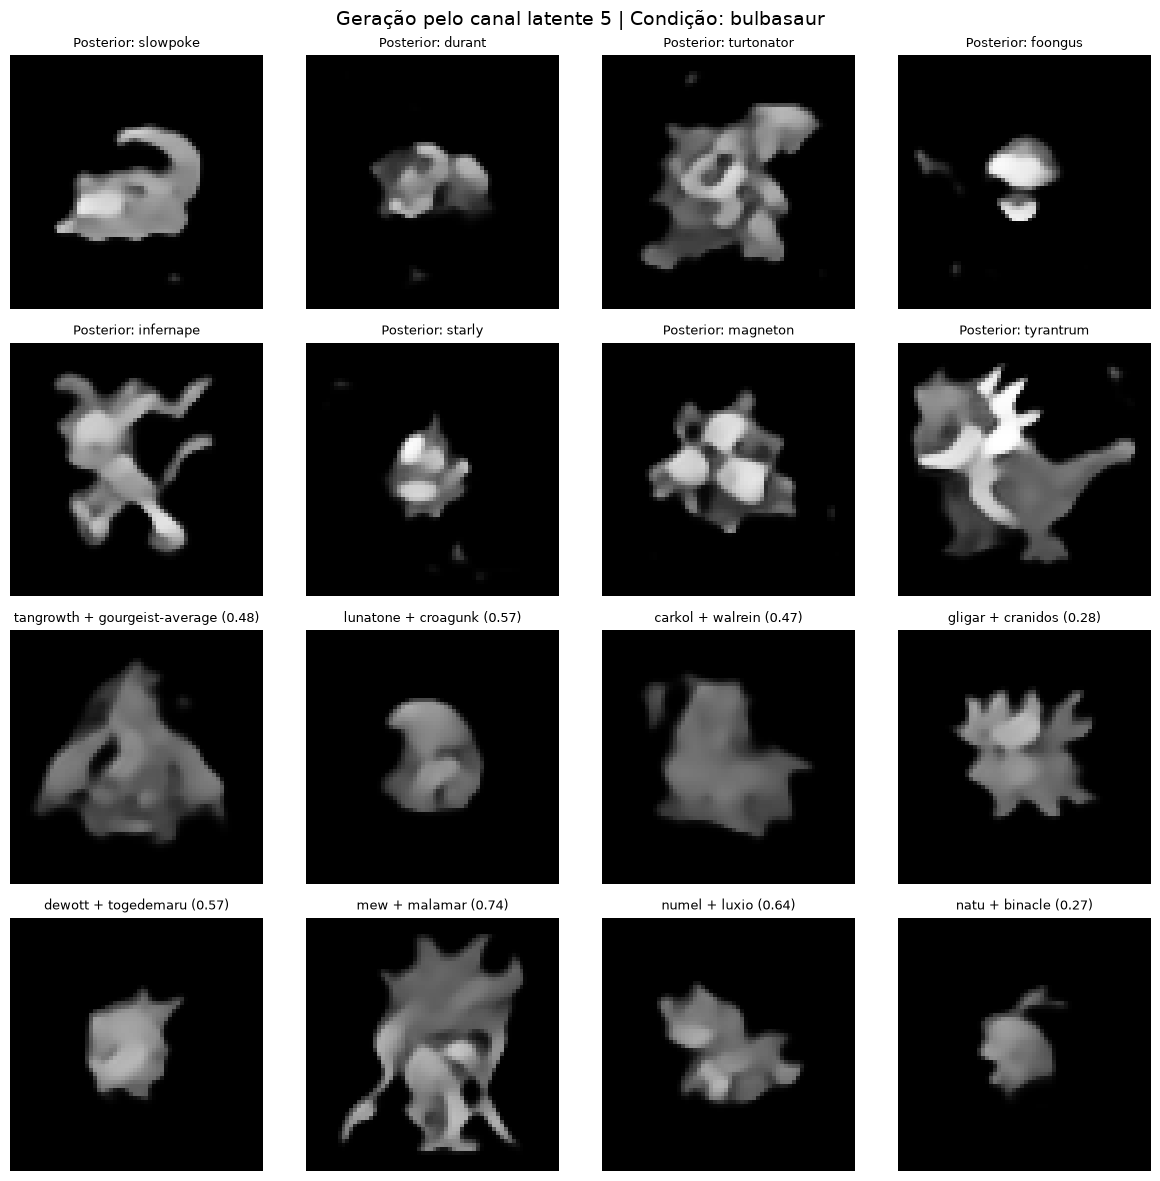

In [39]:
# ==========================================
# CONFIGURAÇÕES
# ==========================================

SEED = 42
N_POSTERIOR = 8
N_INTERPOLATION = 8
N_GENERATIONS = N_POSTERIOR + N_INTERPOLATION

TARGET_POKEMON = "bulbasaur"

rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

LATENT_CHANNELS = 16
LATENT_SIZE = 16
TARGET_CHANNEL = 5


# ==========================================
# CONDIÇÃO FIXA
# ==========================================

target_matches = train_df.index[
    train_df["pokemon_name"].str.lower() == TARGET_POKEMON.lower()
].tolist()

if not target_matches:
    raise ValueError(
        f"{TARGET_POKEMON} não foi encontrado no conjunto de treino."
    )

target_idx = target_matches[0]

target_condition = torch.tensor(
    train_df.loc[target_idx, CONDITION_COLS].to_numpy(
        dtype=np.float32
    ),
    device=DEVICE
).unsqueeze(0)

conditions_generation = target_condition.repeat(
    N_GENERATIONS, 1
)


# ==========================================
# SELECIONAR MAPAS DO TREINO
# ==========================================

available_indices = np.array([
    i for i in range(len(train_df))
    if i != target_idx
])

# Fontes para amostragem posterior
posterior_sources = rng.choice(
    available_indices,
    size=N_POSTERIOR,
    replace=False
)

# Fontes para interpolação
interpolation_pairs = []

for _ in range(N_INTERPOLATION):

    a, b = rng.choice(
        available_indices,
        size=2,
        replace=False
    )

    alpha = rng.uniform(0.25, 0.75)

    interpolation_pairs.append((a, b, alpha))


# ==========================================
# CONSTRUIR OS MAPAS LATENTES
# ==========================================

latent_maps = []
generation_labels = []

# ------------------------------------------
# 1. Amostragem posterior
# ------------------------------------------

for source_idx in posterior_sources:

    mu5 = mu5_bank[source_idx]
    std5 = std5_bank[source_idx]

    epsilon = torch.randn_like(mu5)

    # z5 ~ q(z5 | Pokémon de origem)
    z5 = mu5 + std5 * epsilon

    latent_maps.append(z5)

    source_name = train_df.loc[
        source_idx, "pokemon_name"
    ]

    generation_labels.append(
        f"Posterior: {source_name}"
    )


# ------------------------------------------
# 2. Interpolação entre mapas
# ------------------------------------------

for a, b, alpha in interpolation_pairs:

    mu_a = mu5_bank[a]
    mu_b = mu5_bank[b]

    # Interpolação linear entre os mapas espaciais
    z5 = (1 - alpha) * mu_a + alpha * mu_b

    latent_maps.append(z5)

    name_a = train_df.loc[a, "pokemon_name"]
    name_b = train_df.loc[b, "pokemon_name"]

    generation_labels.append(
        f"{name_a} + {name_b} ({alpha:.2f})"
    )


# ==========================================
# MONTAR O LATENTE COMPLETO
# ==========================================

# Os outros 15 canais recebem amostras do prior
z = torch.randn(
    N_GENERATIONS,
    LATENT_CHANNELS,
    LATENT_SIZE,
    LATENT_SIZE,
    device=DEVICE
)

# Substituir o canal 5 pelos mapas construídos
z[:, TARGET_CHANNEL] = torch.stack(
    latent_maps
).to(DEVICE)


# ==========================================
# DECODIFICAR
# ==========================================

model.eval()

with torch.no_grad():

    generated_images = model.decoder(
        z,
        conditions_generation
    )

generated_images = generated_images.cpu()


# ==========================================
# VISUALIZAR
# ==========================================

fig, axes = plt.subplots(
    4, 4,
    figsize=(12, 12)
)

axes = axes.flatten()

for i in range(N_GENERATIONS):

    axes[i].imshow(
        generated_images[i, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i].set_title(
        generation_labels[i],
        fontsize=9
    )

    axes[i].axis("off")

plt.suptitle(
    f"Geração pelo canal latente 5 | Condição: {TARGET_POKEMON}",
    fontsize=14
)

plt.tight_layout()
plt.show()

Pokémon A: mew
Pokémon B: malamar


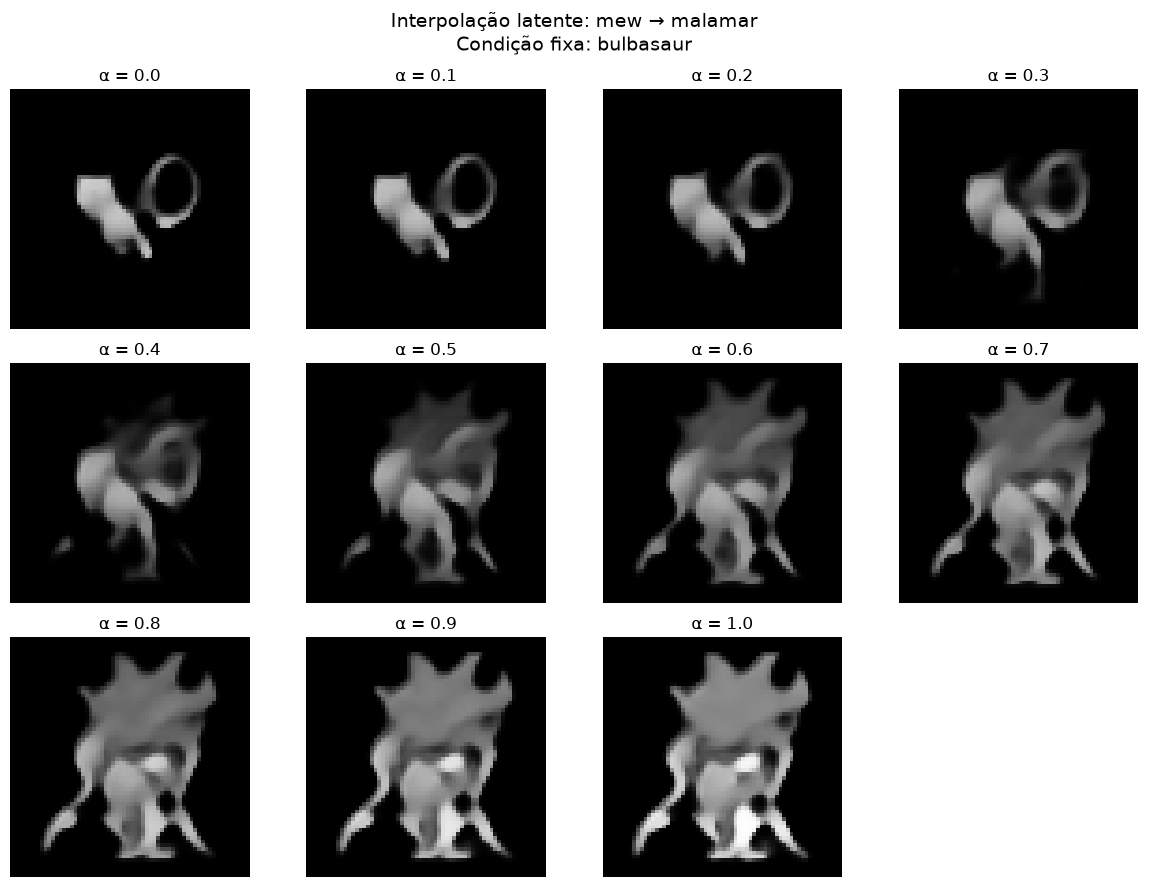


Diferença entre imagens consecutivas:
α 0.0 → 0.1: 0.005850
α 0.1 → 0.2: 0.006562
α 0.2 → 0.3: 0.009074
α 0.3 → 0.4: 0.015581
α 0.4 → 0.5: 0.025950
α 0.5 → 0.6: 0.024662
α 0.6 → 0.7: 0.021381
α 0.7 → 0.8: 0.023516
α 0.8 → 0.9: 0.022114
α 0.9 → 1.0: 0.023332


In [40]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# CONFIGURAÇÕES
# ==========================================

SOURCE_A = "mew"
SOURCE_B = "malamar"

TARGET_POKEMON = "bulbasaur"

N_STEPS = 11
LATENT_CHANNEL = 5

model.eval()

# ==========================================
# LOCALIZAR OS POKÉMON NO TREINO
# ==========================================

def get_train_index(pokemon_name):

    matches = train_df.index[
        train_df["pokemon_name"].str.lower() == pokemon_name.lower()
    ].tolist()

    if not matches:
        raise ValueError(
            f"{pokemon_name} não encontrado no conjunto de treino."
        )

    return matches[0]


idx_a = get_train_index(SOURCE_A)
idx_b = get_train_index(SOURCE_B)

print("Pokémon A:", train_df.loc[idx_a, "pokemon_name"])
print("Pokémon B:", train_df.loc[idx_b, "pokemon_name"])


# ==========================================
# OBTER OS MAPAS LATENTES
# ==========================================

mu_a = mu5_bank[idx_a].to(DEVICE)
mu_b = mu5_bank[idx_b].to(DEVICE)

# Valores de interpolação
alphas = torch.linspace(
    0, 1, N_STEPS,
    device=DEVICE
)

# Interpolação dos mapas
interpolated_maps = torch.stack([
    (1 - alpha) * mu_a + alpha * mu_b
    for alpha in alphas
])


# ==========================================
# CONDIÇÃO FIXA: BULBASAUR
# ==========================================

condition_idx = get_train_index(TARGET_POKEMON)

condition = torch.tensor(
    train_df.loc[
        condition_idx, CONDITION_COLS
    ].to_numpy(dtype=np.float32),
    device=DEVICE
).unsqueeze(0)

conditions = condition.repeat(N_STEPS, 1)


# ==========================================
# CONSTRUIR O ESPAÇO LATENTE
# ==========================================

torch.manual_seed(42)

# Os outros 15 canais permanecem iguais
# em todas as posições da interpolação
z = torch.randn(
    N_STEPS,
    16,
    16,
    16,
    device=DEVICE
)

# Substituir canal 5 pela interpolação
z[:, LATENT_CHANNEL] = interpolated_maps


# ==========================================
# GERAR IMAGENS
# ==========================================

with torch.no_grad():

    generated = model.decoder(
        z,
        conditions
    )

generated = generated.cpu()


# ==========================================
# VISUALIZAR
# ==========================================

fig, axes = plt.subplots(
    3, 4,
    figsize=(12, 9)
)

axes = axes.flatten()

for i in range(N_STEPS):

    axes[i].imshow(
        generated[i, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i].set_title(
        f"α = {alphas[i].item():.1f}"
    )

    axes[i].axis("off")

for i in range(N_STEPS, len(axes)):
    axes[i].axis("off")

plt.suptitle(
    f"Interpolação latente: {SOURCE_A} → {SOURCE_B}\n"
    f"Condição fixa: {TARGET_POKEMON}",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ==========================================
# QUANTIFICAR A TRANSIÇÃO
# ==========================================

adjacent_mae = (
    generated[1:] - generated[:-1]
).abs().mean(dim=(1, 2, 3))

print("\nDiferença entre imagens consecutivas:")

for i, value in enumerate(adjacent_mae):

    print(
        f"α {alphas[i].item():.1f} → "
        f"{alphas[i+1].item():.1f}: "
        f"{value.item():.6f}"
    )

In [42]:
print("Condição fixa:")

condition_series = pd.Series(
    conditions[0].cpu().numpy(),
    index=CONDITION_COLS
)

display(condition_series)

print(
    "Todas as condições são iguais:",
    torch.equal(
        conditions,
        conditions[0:1].expand_as(conditions)
    )
)

Condição fixa:


type_normal             0.000000
type_fire               0.000000
type_water              0.000000
type_electric           0.000000
type_grass              1.000000
type_ice                0.000000
type_fighting           0.000000
type_poison             1.000000
type_ground             0.000000
type_flying             0.000000
type_psychic            0.000000
type_bug                0.000000
type_rock               0.000000
type_ghost              0.000000
type_dragon             0.000000
type_dark               0.000000
type_steel              0.000000
type_fairy              0.000000
hp_norm                 0.176471
attack_norm             0.192157
defense_norm            0.192157
special_attack_norm     0.254902
special_defense_norm    0.254902
speed_norm              0.176471
dtype: float32

Todas as condições são iguais: True


In [41]:
# ==========================================
# CONSTRUIR O ESPAÇO LATENTE CORRETAMENTE
# ==========================================

torch.manual_seed(42)

# Criar uma única amostra aleatória
z_base = torch.randn(
    1,
    16,
    16,
    16,
    device=DEVICE
)

# Replicar exatamente a mesma amostra
# para todas as posições da interpolação
z = z_base.repeat(
    N_STEPS,
    1,
    1,
    1
)

# Modificar exclusivamente o canal 5
z[:, LATENT_CHANNEL] = interpolated_maps


# ==========================================
# VERIFICAR O CONTROLE DO EXPERIMENTO
# ==========================================

# Conferir condições
conditions_fixed = torch.equal(
    conditions,
    conditions[0:1].expand_as(conditions)
)

# Conferir os outros 15 canais
other_channels = torch.cat(
    [z[:, :LATENT_CHANNEL], z[:, LATENT_CHANNEL + 1:]],
    dim=1
)

other_channels_fixed = torch.allclose(
    other_channels,
    other_channels[0:1].expand_as(other_channels)
)

print("Condições fixas:", conditions_fixed)
print("Outros 15 canais fixos:", other_channels_fixed)

assert conditions_fixed
assert other_channels_fixed

Condições fixas: True
Outros 15 canais fixos: True


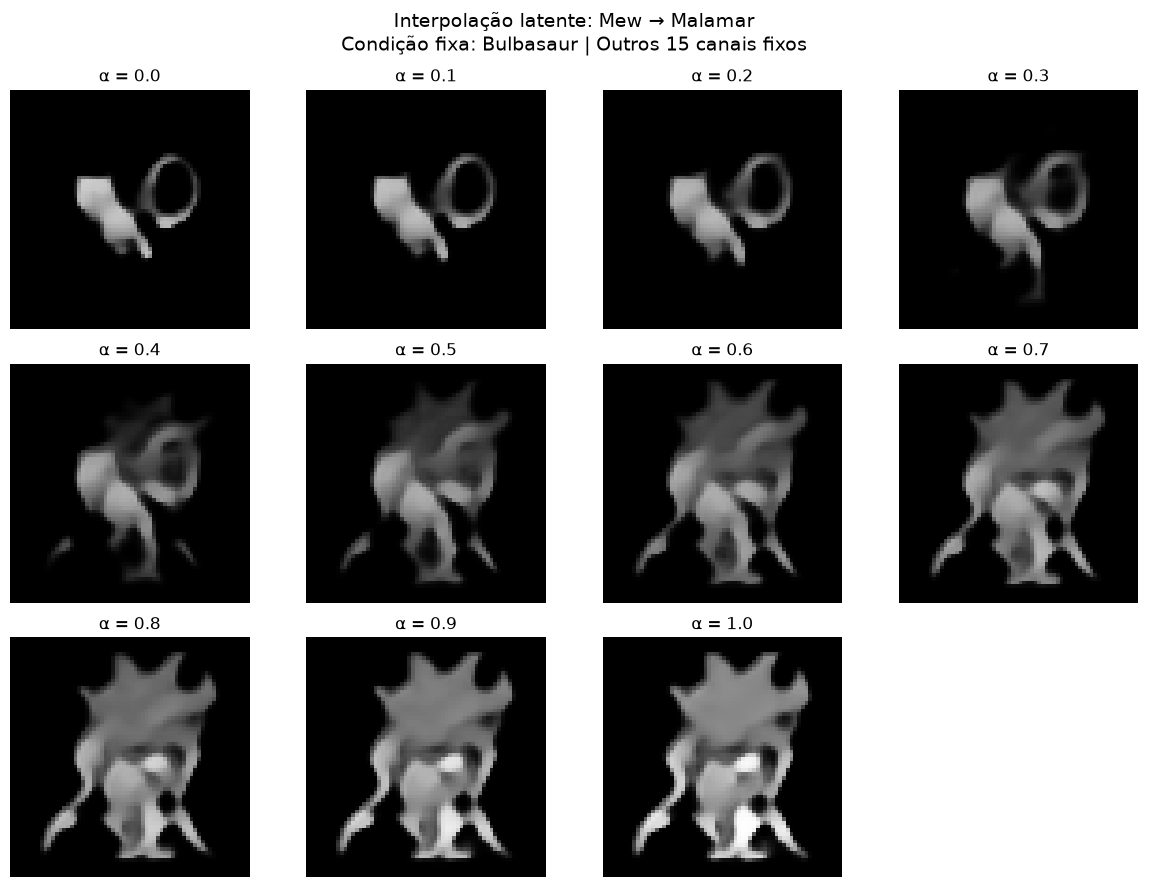

Diferença entre imagens consecutivas:
α 0.0 → 0.1: 0.005534
α 0.1 → 0.2: 0.006427
α 0.2 → 0.3: 0.009300
α 0.3 → 0.4: 0.017358
α 0.4 → 0.5: 0.023656
α 0.5 → 0.6: 0.023776
α 0.6 → 0.7: 0.022668
α 0.7 → 0.8: 0.022590
α 0.8 → 0.9: 0.022222
α 0.9 → 1.0: 0.022774


In [43]:
# Gerar imagens com o espaço latente controlado
model.eval()

with torch.no_grad():
    generated = model.decoder(z, conditions)

generated = generated.cpu()

# Visualizar interpolação
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.flatten()

for i in range(N_STEPS):

    axes[i].imshow(
        generated[i, 0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[i].set_title(f"α = {alphas[i].item():.1f}")
    axes[i].axis("off")

for i in range(N_STEPS, len(axes)):
    axes[i].axis("off")

plt.suptitle(
    "Interpolação latente: Mew → Malamar\n"
    "Condição fixa: Bulbasaur | Outros 15 canais fixos",
    fontsize=14
)

plt.tight_layout()
plt.show()


# Diferença entre imagens consecutivas
adjacent_mae = (
    generated[1:] - generated[:-1]
).abs().mean(dim=(1, 2, 3))

print("Diferença entre imagens consecutivas:")

for i, value in enumerate(adjacent_mae):
    print(
        f"α {alphas[i].item():.1f} → "
        f"{alphas[i+1].item():.1f}: "
        f"{value.item():.6f}"
    )

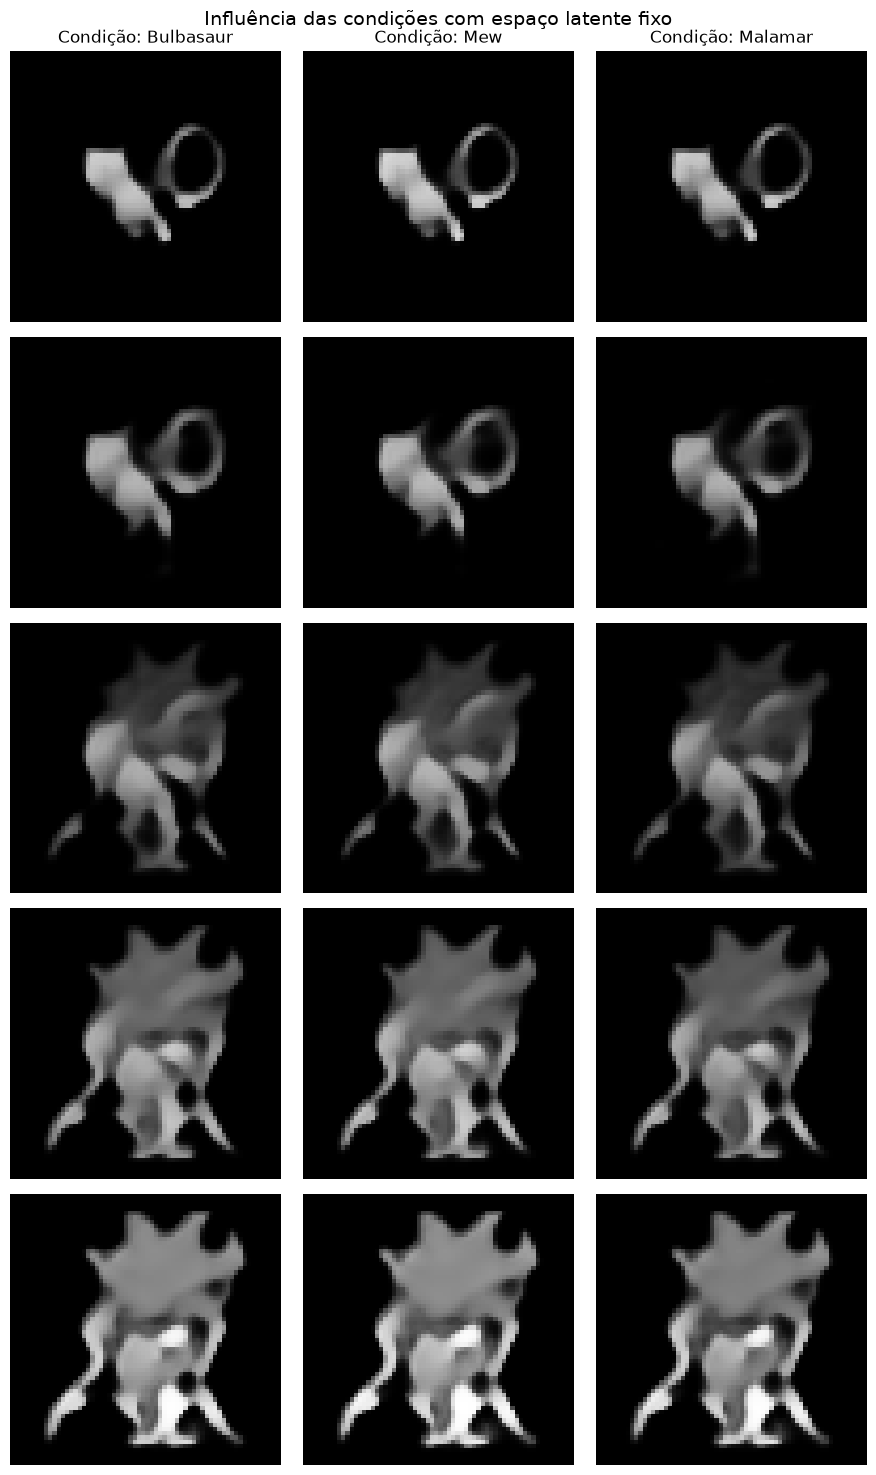


Alpha = 0.00
Bulbasaur vs. Mew: MAE = 0.003340
Bulbasaur vs. Malamar: MAE = 0.003858

Alpha = 0.25
Bulbasaur vs. Mew: MAE = 0.004096
Bulbasaur vs. Malamar: MAE = 0.005967

Alpha = 0.50
Bulbasaur vs. Mew: MAE = 0.007420
Bulbasaur vs. Malamar: MAE = 0.009510

Alpha = 0.75
Bulbasaur vs. Mew: MAE = 0.007784
Bulbasaur vs. Malamar: MAE = 0.013197

Alpha = 1.00
Bulbasaur vs. Mew: MAE = 0.010471
Bulbasaur vs. Malamar: MAE = 0.014274


In [44]:
import torch
import matplotlib.pyplot as plt
import numpy as np

model.eval()

# Pontos da interpolação
alphas_test = torch.tensor(
    [0.0, 0.25, 0.5, 0.75, 1.0],
    device=DEVICE
)

N = len(alphas_test)

# ==========================================
# 1. CONSTRUIR OS MAPAS LATENTES
# ==========================================

# Utilizar os mapas de Mew e Malamar já extraídos
z5_interpolated = torch.stack([
    (1 - alpha) * mu_a + alpha * mu_b
    for alpha in alphas_test
])

# Fixar os outros 15 canais
torch.manual_seed(42)

z_base = torch.randn(
    1, 16, 16, 16,
    device=DEVICE
)

z_test = z_base.repeat(N, 1, 1, 1)

z_test[:, 5] = z5_interpolated


# ==========================================
# 2. OBTER AS TRÊS CONDIÇÕES
# ==========================================

pokemon_conditions = {}

for name in ["bulbasaur", "mew", "malamar"]:

    idx = get_train_index(name)

    condition = torch.tensor(
        train_df.loc[idx, CONDITION_COLS].to_numpy(
            dtype=np.float32
        ),
        device=DEVICE
    )

    pokemon_conditions[name] = condition


# Repetir cada condição para os cinco valores de alpha
conditions_test = torch.cat([
    pokemon_conditions[name].unsqueeze(0).repeat(N, 1)
    for name in ["bulbasaur", "mew", "malamar"]
], dim=0)


# Repetir os mesmos mapas latentes para as três condições
z_repeated = z_test.repeat(3, 1, 1, 1)


# ==========================================
# 3. GERAR
# ==========================================

with torch.no_grad():

    generated = model.decoder(
        z_repeated,
        conditions_test
    )

generated = generated.cpu().reshape(
    3, N, 1, 64, 64
)


# ==========================================
# 4. VISUALIZAR
# ==========================================

fig, axes = plt.subplots(
    N, 3,
    figsize=(9, 3 * N)
)

condition_names = [
    "Bulbasaur",
    "Mew",
    "Malamar"
]

for j, name in enumerate(condition_names):
    axes[0, j].set_title(f"Condição: {name}")

for i in range(N):

    for j in range(3):

        axes[i, j].imshow(
            generated[j, i, 0],
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[i, j].axis("off")

    axes[i, 0].set_ylabel(
        f"α = {alphas_test[i].item():.2f}",
        rotation=0,
        labelpad=35,
        va="center"
    )

plt.suptitle(
    "Influência das condições com espaço latente fixo",
    fontsize=14
)

plt.tight_layout()
plt.show()


# ==========================================
# 5. QUANTIFICAR A INFLUÊNCIA
# ==========================================

# Comparar as saídas com Bulbasaur como referência
for i, alpha in enumerate(alphas_test):

    reference = generated[0, i]

    print(f"\nAlpha = {alpha.item():.2f}")

    for j, name in enumerate(condition_names[1:], start=1):

        mae = (
            generated[j, i] - reference
        ).abs().mean().item()

        print(f"Bulbasaur vs. {name}: MAE = {mae:.6f}")